# Explore the movie data

This notebook is for exploratory analysis after the normalized movie tables have passed the data-quality profiling step. It loads the local cache without making API requests.


In [1]:
from IPython.display import display
import pandas as pd

from streamvault.cache import load_cached_records
from streamvault.config import CONFIG
from streamvault.normalize import normalize_movie_records

records = list(load_cached_records(CONFIG.cache_file).values())
tables = normalize_movie_records(records)
movies = tables.movies

frames = {
    name: getattr(tables, name)
    for name in (
        "movies", "genres", "movie_genres", "companies",
        "movie_companies", "countries", "movie_origin_countries",
        "movie_production_countries", "languages",
        "movie_spoken_languages", "collections", "people",
        "cast_credits", "crew_credits",
    )
}

print(f"Loaded {len(records):,} cached movie records")
if not records:
    print("No cached movies yet. Run `uv run streamvault` first.")

# Format to 4 decimal places with comma separators (e.g., 108,446,000.00)
pd.set_option('display.float_format', '{:,.4f}'.format)


Loaded 112 cached movie records


## 3. Numeric movie fields and unusual values

Use quantiles and interquartile-range (IQR) bounds to locate values worth checking. These bounds are exploratory, not universal validity rules; budget and revenue may be zero or absent, for example, and an extreme value may be legitimate.


In [2]:
identifier_columns = {"movie_id", "collection_id"}
numeric_movie_columns = [
    column
    for column in movies.select_dtypes(include="number").columns
    if column not in identifier_columns
]

if numeric_movie_columns:
    numeric_summary = movies[numeric_movie_columns].describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.90, 0.99]
    ).T
    display(numeric_summary)
else:
    print("No numeric movie measures are available.")

outlier_rows = []
for column in numeric_movie_columns:
    values = pd.to_numeric(movies[column], errors="coerce")
    valid_values = values.dropna()
    if valid_values.empty:
        continue

    q1 = valid_values.quantile(0.25)
    q3 = valid_values.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    unusual = values.lt(lower_bound) | values.gt(upper_bound)
    examples = movies.loc[unusual, ["movie_id", column]].head(5)

    outlier_rows.append(
        {
            "field": column,
            "iqr_lower_bound": lower_bound,
            "iqr_upper_bound": upper_bound,
            "values_outside_iqr": int(unusual.sum()),
            "negative_values": int(valid_values.lt(0).sum()),
            "example_movie_values": [
                f"{row.movie_id}: {row_value}"
                for row, row_value in zip(
                    examples.itertuples(index=False),
                    examples[column],
                    strict=True,
                )
            ],
        }
    )

outlier_review = pd.DataFrame(outlier_rows)
display(outlier_review)


,count,mean,std,min,1%,25%,50%,75%,90%,99%,max
budget,112.0000,"108,445,982.1429","82,788,177.8615","1,200,000.0000","4,665,000.0000","38,087,500.0000","91,000,000.0000","150,000,000.0000","229,000,000.0000","349,840,000.0000","379,000,000.0000"
popularity,112.0000,19.6574,13.4498,0.4583,1.0591,10.3549,16.3064,23.9677,36.8038,65.7337,89.1177
revenue,112.0000,"599,658,765.7411","436,246,692.9360","7,390,108.0000","29,502,907.4100","295,346,340.0000","519,563,017.5000","872,698,393.5000","1,057,280,933.6000","1,993,719,091.3600","2,942,649,778.0000"
runtime,112.0000,130.4911,25.5368,81.0000,81.8800,115.0000,128.5000,143.2500,164.7000,200.3400,202.0000
vote_average,112.0000,7.5887,0.7135,5.7520,6.0359,7.2012,7.7200,8.1645,8.4510,8.6753,8.7340
vote_count,112.0000,"17,538.3214","8,270.0406","4,136.0000","5,959.5000","11,039.0000","15,841.0000","22,821.5000","29,265.2000","40,713.8500","41,925.0000"


,field,iqr_lower_bound,iqr_upper_bound,values_outside_iqr,negative_values,example_movie_values
0,budget,"-129,781,250.0000","317,868,750.0000",2,0,"[299534: 356000000, 1865: 379000000]"
1,popularity,-10.0644,44.3869,6,0,"[155: 66.8926, 278: 45.4678, 299534: 89.1177, ..."
2,revenue,"-570,681,740.2500","1,738,726,473.7500",2,0,"[299534: 2942649778, 299536: 2052415039]"
3,runtime,72.6250,185.6250,3,0,"[122: 201, 240: 202, 424: 195]"
4,vote_average,5.7564,9.6094,1,0,[41513: 5.752]
5,vote_count,"-6,634.7500","40,495.2500",2,0,"[27205: 40754, 157336: 41925]"


#### 3b. Investigating the unusual values
IQR flags are screening candidates, not validity rules. The checks below separate missing or negative values from plausible tail observations, and compare each candidate with related fields before drawing a preliminary conclusion.

In [3]:
investigation_movies = movies.copy()
if "release_date" in investigation_movies.columns:
    investigation_movies["release_year"] = investigation_movies["release_date"].dt.year

unusual_details = []
for column in numeric_movie_columns:
    values = pd.to_numeric(investigation_movies[column], errors="coerce")
    valid_values = values.dropna()
    if valid_values.empty:
        continue

    q1 = valid_values.quantile(0.25)
    q3 = valid_values.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    unusual = values.lt(lower_bound) | values.gt(upper_bound)

    for row in investigation_movies.loc[unusual].itertuples(index=False):
        value = getattr(row, column)
        unusual_details.append(
            {
                "field": column,
                "movie_id": row.movie_id,
                "title": row.title if "title" in investigation_movies.columns else pd.NA,
                "release_year": (
                    getattr(row, "release_year")
                    if "release_year" in investigation_movies.columns
                    else pd.NA
                ),
                "value": value,
                "tail": "low" if value < lower_bound else "high",
                "iqr_lower_bound": lower_bound,
                "iqr_upper_bound": upper_bound,
            }
        )

unusual_detail_table = pd.DataFrame(unusual_details)
display(unusual_detail_table)

,field,movie_id,title,release_year,value,tail,iqr_lower_bound,iqr_upper_bound
0,budget,299534,Avengers: Endgame,2019,"356,000,000.0000",high,"-129,781,250.0000","317,868,750.0000"
1,budget,1865,Pirates of the Caribbean: On Stranger Tides,2011,"379,000,000.0000",high,"-129,781,250.0000","317,868,750.0000"
2,popularity,155,The Dark Knight,2008,66.8926,high,-10.0644,44.3869
3,popularity,278,The Shawshank Redemption,1994,45.4678,high,-10.0644,44.3869
4,popularity,299534,Avengers: Endgame,2019,89.1177,high,-10.0644,44.3869
5,popularity,27205,Inception,2010,45.4139,high,-10.0644,44.3869
6,popularity,299536,Avengers: Infinity War,2018,49.4655,high,-10.0644,44.3869
7,popularity,157336,Interstellar,2014,56.3569,high,-10.0644,44.3869
8,revenue,299534,Avengers: Endgame,2019,"2,942,649,778.0000",high,"-570,681,740.2500","1,738,726,473.7500"
9,revenue,299536,Avengers: Infinity War,2018,"2,052,415,039.0000",high,"-570,681,740.2500","1,738,726,473.7500"


##### Financial values: budget and revenue
These checks look for contradictory signs or scale errors, not merely large nominal amounts. A large budget or revenue is possible for a blockbuster; a revenue below zero, a negative budget, or a ratio that lacks a sensible explanation would be a stronger anomaly signal.

In [4]:
financial_columns = [column for column in ("budget", "revenue") if column in investigation_movies.columns]
if financial_columns:
    financial = investigation_movies[["movie_id", "title", "release_year", *financial_columns]].copy()
    for column in financial_columns:
        financial[f"{column}_missing"] = financial[column].isna()
        financial[f"{column}_negative"] = financial[column].lt(0)
        financial[f"{column}_zero"] = financial[column].eq(0)

    if "budget" in financial and "revenue" in financial:
        financial["revenue_budget_ratio"] = financial["revenue"] / financial["budget"].replace(0, pd.NA)

    print("Financial integrity checks:")
    for column in financial_columns:
        values = pd.to_numeric(financial[column], errors="coerce")
        print(
            f"{column}: missing={values.isna().sum()}, zero={values.eq(0).sum()}, "
            f"negative={values.lt(0).sum()}"
        )

    financial_extreme_ids = set(
        unusual_detail_table.loc[
            unusual_detail_table["field"].isin(financial_columns), "movie_id"
        ]
    )
    if financial_extreme_ids:
        display(financial.loc[financial["movie_id"].isin(financial_extreme_ids)].sort_values("movie_id").reset_index(drop=True))

    if "revenue_budget_ratio" in financial:
        ratio_summary = financial["revenue_budget_ratio"].describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.99])
        print("Revenue/budget ratio summary (infinite values excluded):")
        display(ratio_summary.to_frame("ratio").T)

        ratio_candidates = financial.loc[
            financial["revenue_budget_ratio"].notna()
            & (financial["revenue_budget_ratio"] < 0),
            ["movie_id", "title", "release_year", "budget", "revenue", "revenue_budget_ratio"],
        ]
        if not ratio_candidates.empty:
            display(ratio_candidates)
        else:
            print("No negative revenue/budget ratios; no ratio with a negative numerator or denominator was found.")

Financial integrity checks:
budget: missing=0, zero=0, negative=0
revenue: missing=0, zero=0, negative=0


,movie_id,title,release_year,budget,revenue,budget_missing,budget_negative,budget_zero,revenue_missing,revenue_negative,revenue_zero,revenue_budget_ratio
0,1865,Pirates of the Caribbean: On Stranger Tides,2011,379000000,1046721266,False,False,False,False,False,False,2.7618
1,299534,Avengers: Endgame,2019,356000000,2942649778,False,False,False,False,False,False,8.2659
2,299536,Avengers: Infinity War,2018,300000000,2052415039,False,False,False,False,False,False,6.8414


Revenue/budget ratio summary (infinite values excluded):


,count,mean,std,min,25%,50%,75%,90%,99%,max
ratio,112.0000,8.5036,10.3771,1.1337,3.7969,5.3741,8.8502,14.5937,64.3331,70.4907


No negative revenue/budget ratios; no ratio with a negative numerator or denominator was found.


##### Runtime values
The IQR high runtime candidates are reviewed with neighboring runtimes and release context. Runtime units, missing values, and a clearly implausible duration would be stronger anomaly evidence than being above a percentile bound.

In [5]:
if "runtime" in investigation_movies.columns:
    runtimes = pd.to_numeric(investigation_movies["runtime"], errors="coerce")
    print(
        f"runtime: missing={runtimes.isna().sum()}, zero={runtimes.eq(0).sum()}, "
        f"negative={runtimes.lt(0).sum()}"
    )
    runtime_extremes = unusual_detail_table.loc[unusual_detail_table["field"] == "runtime"]
    if not runtime_extremes.empty:
        display(
            investigation_movies.loc[
                investigation_movies["movie_id"].isin(runtime_extremes["movie_id"]),
                ["movie_id", "title", "release_year", "runtime"],
            ].sort_values("runtime", ascending=False).reset_index(drop=True)
        )
    print("Longest runtimes overall:")
    display(
        investigation_movies.sort_values("runtime", ascending=False)[
            ["movie_id", "title", "release_year", "runtime", "vote_average"]
        ].head(12).reset_index(drop=True)
    )

runtime: missing=0, zero=0, negative=0


,movie_id,title,release_year,runtime
0,240,The Godfather Part II,1974,202
1,122,The Lord of the Rings: The Return of the King,2003,201
2,424,Schindler's List,1993,195


Longest runtimes overall:


,movie_id,title,release_year,runtime,vote_average
0,240,The Godfather Part II,1974,202,8.5730
1,122,The Lord of the Rings: The Return of the King,2003,201,8.5070
2,424,Schindler's List,1993,195,8.5700
3,299534,Avengers: Endgame,2019,181,8.2470
4,121,The Lord of the Rings: The Two Towers,2002,179,8.4330
5,120,The Lord of the Rings: The Fellowship of the Ring,2001,179,8.4510
6,238,The Godfather,1972,175,8.6880
7,111,Scarface,1983,170,8.1540
8,49051,The Hobbit: An Unexpected Journey,2012,169,7.3890
9,285,Pirates of the Caribbean: At World's End,2007,169,7.2810


##### Popularity and vote metrics
Popularity, vote count, and vote average measure different things. A high-popularity movie may have strong audience engagement; it is not necessarily duplicated or erroneous. Likewise, a low rating can be plausible when supported by nearby ratings and a meaningful vote count.

In [6]:
metric_columns = [
    column
    for column in ("popularity", "vote_count", "vote_average")
    if column in investigation_movies.columns
]
for column in metric_columns:
    values = pd.to_numeric(investigation_movies[column], errors="coerce")
    print(
        f"{column}: missing={values.isna().sum()}, zero={values.eq(0).sum()}, "
        f"negative={values.lt(0).sum()}"
    )

if "popularity" in investigation_movies:
    print("Highest popularity candidates:")
    display(
        investigation_movies.sort_values("popularity", ascending=False)[
            ["movie_id", "title", "release_year", "popularity", "vote_count", "vote_average"]
        ].head(12).reset_index(drop=True)
    )

if "vote_average" in investigation_movies:
    print("Lowest vote averages:")
    display(
        investigation_movies.sort_values("vote_average", ascending=True)[
            ["movie_id", "title", "release_year", "vote_average", "vote_count", "popularity"]
        ].head(15).reset_index(drop=True)
    )

if "vote_count" in investigation_movies:
    print("Highest vote-count candidates:")
    display(
        investigation_movies.sort_values("vote_count", ascending=False)[
            ["movie_id", "title", "release_year", "vote_count", "popularity", "vote_average"]
        ].head(12).reset_index(drop=True)
    )

engagement_columns = [
    column
    for column in ("popularity", "vote_count", "vote_average", "budget", "revenue", "runtime")
    if column in investigation_movies.columns
]
print("Cross-field Pearson correlations:")
display(investigation_movies[engagement_columns].corr().round(3))

popularity: missing=0, zero=0, negative=0
vote_count: missing=0, zero=0, negative=0
vote_average: missing=0, zero=0, negative=0
Highest popularity candidates:


,movie_id,title,release_year,popularity,vote_count,vote_average
0,299534,Avengers: Endgame,2019,89.1177,29384,8.2470
1,155,The Dark Knight,2008,66.8926,37405,8.5400
2,157336,Interstellar,2014,56.3569,41925,8.4930
3,299536,Avengers: Infinity War,2018,49.4655,33418,8.2470
4,278,The Shawshank Redemption,1994,45.4678,31864,8.7340
5,27205,Inception,2010,45.4139,40754,8.4000
6,671,Harry Potter and the Philosopher's Stone,2001,43.3460,30644,7.9050
7,24428,The Avengers,2012,42.1051,40389,8.0850
8,238,The Godfather,1972,40.7425,23999,8.6880
9,120,The Lord of the Rings: The Fellowship of the Ring,2001,39.3976,28890,8.4510


Lowest vote averages:


,movie_id,title,release_year,vote_average,vote_count,popularity
0,41513,The Smurfs,2011,5.7520,4136,5.4347
1,217,Indiana Jones and the Kingdom of the Crystal S...,2008,6.0270,9386,7.9677
2,534,Terminator Salvation,2009,6.1080,7360,8.2923
3,955,Mission: Impossible II,2000,6.1400,7967,7.7691
4,8078,Alien Resurrection,1997,6.1700,5877,7.7192
5,331,Jurassic Park III,2001,6.1790,8195,0.4583
6,296,Terminator 3: Rise of the Machines,2003,6.2160,7641,9.4087
7,810,Shrek the Third,2007,6.3170,10138,11.1544
8,8077,Alien³,1992,6.4000,6722,7.7480
9,10192,Shrek Forever After,2010,6.4160,8237,13.7726


Highest vote-count candidates:


,movie_id,title,release_year,vote_count,popularity,vote_average
0,157336,Interstellar,2014,41925,56.3569,8.4930
1,27205,Inception,2010,40754,45.4139,8.4000
2,24428,The Avengers,2012,40389,42.1051,8.0850
3,155,The Dark Knight,2008,37405,66.8926,8.5400
4,299536,Avengers: Infinity War,2018,33418,49.4655,8.2470
5,550,Fight Club,1999,33362,33.3477,8.4000
6,278,The Shawshank Redemption,1994,31864,45.4678,8.7340
7,680,Pulp Fiction,1994,31350,29.9893,8.4800
8,13,Forrest Gump,1994,30907,28.9685,8.4620
9,671,Harry Potter and the Philosopher's Stone,2001,30644,43.3460,7.9050


Cross-field Pearson correlations:


,popularity,vote_count,vote_average,budget,revenue,runtime
popularity,1.0000,0.8300,0.5920,0.2630,0.5080,0.4840
vote_count,0.8300,1.0000,0.6590,0.2000,0.4070,0.4300
vote_average,0.5920,0.6590,1.0000,-0.3230,-0.0210,0.4180
budget,0.2630,0.2000,-0.3230,1.0000,0.7460,0.1990
revenue,0.5080,0.4070,-0.0210,0.7460,1.0000,0.2570
runtime,0.4840,0.4300,0.4180,0.1990,0.2570,1.0000


##### Preliminary review of the unusual fields
The following decisions are based on the current cache. They can be revisited if cache records are refreshed or a project-specific numeric rule is approved.

In [7]:
field_verdicts = [
    {
        "field": "budget",
        "flagged_movies": "Pirates of the Caribbean: On Stranger Tides; Avengers: Endgame",
        "evidence_of_normality": "Both values are positive and the films are known large-budget blockbusters; no negative or missing values occur.",
        "evidence_of_concern": "Nominal budgets are high and sit above the IQR upper bound.",
        "preliminary_conclusion": "Normal extreme",
    },
    {
        "field": "revenue",
        "flagged_movies": "Avengers: Endgame; Avengers: Infinity War",
        "evidence_of_normality": "Positive ratios and global blockbuster context support the high observations; no missing, zero, or negative values occur.",
        "evidence_of_concern": "Both values exceed the IQR upper bound and rank at the top of this cache.",
        "preliminary_conclusion": "Normal extreme",
    },
    {
        "field": "runtime",
        "flagged_movies": "The Godfather Part II; The Lord of the Rings: The Return of the King; Schindler's List",
        "evidence_of_normality": "All are positive, complete runtimes and are near other 195–202 minute films.",
        "evidence_of_concern": "Three runtimes exceed the IQR upper bound.",
        "preliminary_conclusion": "Normal extreme",
    },
    {
        "field": "popularity",
        "flagged_movies": "Avengers: Endgame; The Dark Knight; Interstellar; Avengers: Infinity War; Shawshank Redemption; Inception",
        "evidence_of_normality": "High values broadly align with high vote counts and no missing or negative values occur.",
        "evidence_of_concern": "Popularity is a cached/source-derived snapshot and can change independently of static film attributes.",
        "preliminary_conclusion": "Needs source verification",
    },
    {
        "field": "vote_average",
        "flagged_movies": "The Smurfs",
        "evidence_of_normality": "The 5.752 value is inside TMDB's 0–10 scale and is consistent with several nearby low-rated films.",
        "evidence_of_concern": "It is the sole IQR low tail value and has the smallest vote count among the cache.",
        "preliminary_conclusion": "Normal extreme",
    },
    {
        "field": "vote_count",
        "flagged_movies": "Interstellar; Inception",
        "evidence_of_normality": "Both are positive and high, with strong correlation to popularity and vote averages.",
        "evidence_of_concern": "Both exceed the IQR upper bound and are the cache's strongest vote-engagement observations.",
        "preliminary_conclusion": "Normal extreme",
    },
]
display(pd.DataFrame(field_verdicts))

,field,flagged_movies,evidence_of_normality,evidence_of_concern,preliminary_conclusion
0,budget,Pirates of the Caribbean: On Stranger Tides; A...,Both values are positive and the films are kno...,Nominal budgets are high and sit above the IQR...,Normal extreme
1,revenue,Avengers: Endgame; Avengers: Infinity War,Positive ratios and global blockbuster context...,Both values exceed the IQR upper bound and ran...,Normal extreme
2,runtime,The Godfather Part II; The Lord of the Rings: ...,"All are positive, complete runtimes and are ne...",Three runtimes exceed the IQR upper bound.,Normal extreme
3,popularity,Avengers: Endgame; The Dark Knight; Interstell...,High values broadly align with high vote count...,Popularity is a cached/source-derived snapshot...,Needs source verification
4,vote_average,The Smurfs,The 5.752 value is inside TMDB's 0–10 scale an...,It is the sole IQR low tail value and has the ...,Normal extreme
5,vote_count,Interstellar; Inception,"Both are positive and high, with strong correl...",Both exceed the IQR upper bound and are the ca...,Normal extreme


## 4. Model numerical KPI relationships

Move beyond one-variable IQR screens and compare the numeric KPIs jointly. Every record is retained in the source frame. IQR flags are used as sensitivity labels: a record that is flagged by one KPI may still be a legitimate extreme and may still contribute useful evidence.

The goal is exploratory: compare linear and rank relationships, test whether a conclusion changes when flagged rows are excluded, and distinguish a stable relationship from one that depends on a small number of observations.


### 4a. Correlation comparison

Pearson measures linear co-movement. Spearman measures rank co-movement and is generally less affected by scale or extreme observations. A high correlation does not establish causality, and popularity should remain interpreted as a source-derived snapshot.

In [8]:
import numpy as np

kpi_columns = [
    column
    for column in ("budget", "revenue", "runtime", "popularity", "vote_count", "vote_average")
    if column in movies.columns
]
kpi_context_columns = [column for column in ("movie_id", "title", "release_date") if column in movies.columns]
kpi_movies = movies[kpi_context_columns + kpi_columns].copy()
for column in kpi_columns:
    kpi_movies[column] = pd.to_numeric(kpi_movies[column], errors="coerce")

kpi_outlier_bounds = {}
kpi_outlier_flags = pd.DataFrame(False, index=kpi_movies.index, columns=kpi_columns)
for column in kpi_columns:
    values = kpi_movies[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    kpi_outlier_bounds[column] = {"lower": q1 - 1.5 * iqr, "upper": q3 + 1.5 * iqr}
    kpi_outlier_flags[column] = kpi_movies[column].lt(kpi_outlier_bounds[column]["lower"]) | kpi_movies[column].gt(kpi_outlier_bounds[column]["upper"])

complete_kpis = kpi_movies[kpi_columns]
pearson_matrix = complete_kpis.corr(method="pearson")
spearman_matrix = complete_kpis.rank(method="average").corr(method="pearson")

print("Pearson correlations")
display(pearson_matrix.round(3))
print("Spearman correlations")
display(spearman_matrix.round(3))

log_kpis = complete_kpis.copy()
for column in ("budget", "revenue", "popularity", "vote_count"):
    if column in log_kpis:
        log_kpis[column] = np.log10(log_kpis[column].where(log_kpis[column] > 0))

print("Log10 correlations for positive, skewed fields")
display(log_kpis.corr(method="pearson").round(3))

Pearson correlations


,budget,revenue,runtime,popularity,vote_count,vote_average
budget,1.0000,0.7460,0.1990,0.2630,0.2000,-0.3230
revenue,0.7460,1.0000,0.2570,0.5080,0.4070,-0.0210
runtime,0.1990,0.2570,1.0000,0.4840,0.4300,0.4180
popularity,0.2630,0.5080,0.4840,1.0000,0.8300,0.5920
vote_count,0.2000,0.4070,0.4300,0.8300,1.0000,0.6590
vote_average,-0.3230,-0.0210,0.4180,0.5920,0.6590,1.0000


Spearman correlations


,budget,revenue,runtime,popularity,vote_count,vote_average
budget,1.0000,0.7530,0.1990,0.1070,0.1370,-0.4240
revenue,0.7530,1.0000,0.2350,0.2890,0.3650,-0.1440
runtime,0.1990,0.2350,1.0000,0.4940,0.4620,0.4030
popularity,0.1070,0.2890,0.4940,1.0000,0.8690,0.6910
vote_count,0.1370,0.3650,0.4620,0.8690,1.0000,0.6850
vote_average,-0.4240,-0.1440,0.4030,0.6910,0.6850,1.0000


Log10 correlations for positive, skewed fields


,budget,revenue,runtime,popularity,vote_count,vote_average
budget,1.0000,0.7360,0.0560,0.0610,0.0730,-0.4340
revenue,0.7360,1.0000,0.1090,0.1870,0.2510,-0.2000
runtime,0.0560,0.1090,1.0000,0.4370,0.4170,0.4180
popularity,0.0610,0.1870,0.4370,1.0000,0.7490,0.6420
vote_count,0.0730,0.2510,0.4170,0.7490,1.0000,0.7230
vote_average,-0.4340,-0.2000,0.4180,0.6420,0.7230,1.0000


### 4b. Focused relationship models and sensitivity

The following comparisons use complete cases for each pair. "IQR-excluded" means only rows flagged by IQR bounds for that pair are omitted from a comparison copy; it does not remove or overwrite any cached movie record.

In [9]:
relationship_pairs = [
("Budget vs revenue", "budget", "revenue", True),
("Popularity vs vote count", "popularity", "vote_count", True),
("Vote count vs vote average", "vote_count", "vote_average", True),
("Runtime vs vote average", "runtime", "vote_average", False),
("Runtime vs popularity", "runtime", "popularity", True),
("Budget vs vote average", "budget", "vote_average", True),
("Revenue vs vote average", "revenue", "vote_average", True),
    ]

def linear_fit(frame, x_column, y_column):
    pair = frame[[x_column, y_column]].dropna()
    if len(pair) < 3:
        return {"n": len(pair), "slope": np.nan, "r_squared": np.nan}
    x = pair[x_column].to_numpy(dtype=float)
    y = pair[y_column].to_numpy(dtype=float)
    slope, intercept = np.polyfit(x, y, 1)
    fitted = intercept + slope * x
    ss_res = np.sum((y - fitted) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    r_squared = 1 - ss_res / ss_tot if ss_tot else np.nan
    return {"n": len(pair), "slope": slope, "intercept": intercept, "r_squared": r_squared}

relationship_rows = []
for label, x_column, y_column, allow_log in relationship_pairs:
    if x_column not in kpi_movies or y_column not in kpi_movies:
        continue

    pair = kpi_movies[["title", x_column, y_column]].dropna()
    pair_outliers = kpi_outlier_flags[[x_column, y_column]].any(axis=1)
    retained_pair = kpi_movies.loc[~pair_outliers, ["title", x_column, y_column]].dropna()

    all_pearson = pair[x_column].corr(pair[y_column], method="pearson")
    all_spearman = pair[x_column].rank(method="average").corr(pair[y_column].rank(method="average"), method="pearson")
    retained_pearson = retained_pair[x_column].corr(retained_pair[y_column], method="pearson")
    retained_spearman = retained_pair[x_column].rank(method="average").corr(retained_pair[y_column].rank(method="average"), method="pearson")
    all_fit = linear_fit(pair, x_column, y_column)
    retained_fit = linear_fit(retained_pair, x_column, y_column)

    pearson_change = retained_pearson - all_pearson if pd.notna(retained_pearson) and pd.notna(all_pearson) else np.nan
    sign_reversal = (
        pd.notna(all_pearson)
        and pd.notna(retained_pearson)
        and np.sign(all_pearson) != np.sign(retained_pearson)
    )
    if sign_reversal or (pd.notna(pearson_change) and abs(pearson_change) >= 0.20):
        sensitivity = "Sensitive to IQR-flagged rows"
    elif abs(all_pearson) >= 0.50:
        sensitivity = "Stable strong relationship"
    elif abs(all_pearson) < 0.30:
        sensitivity = "No clear linear relationship"
    else:
        sensitivity = "Moderate or inconclusive"

    log_result = ""
    if allow_log:
        log_pair = pair[[x_column, y_column]].copy()
        for column in (x_column, y_column):
            if column in ("budget", "revenue", "popularity", "vote_count"):
                log_pair[column] = np.log10(log_pair[column].where(log_pair[column] > 0))
        log_pair = log_pair.dropna()
        if len(log_pair) >= 3:
            log_pearson = log_pair[x_column].corr(log_pair[y_column], method="pearson")
            log_result = f"{log_pearson:.3f} Pearson on log10 scales"

    relationship_rows.append({
        "relationship": label,
        "n_all": len(pair),
        "pearson_all": all_pearson,
        "spearman_all": all_spearman,
        "n_iqr_excluded": len(retained_pair),
        "pearson_iqr_excluded": retained_pearson,
        "spearman_iqr_excluded": retained_spearman,
        "pearson_change": pearson_change,
        "all_fit_r_squared": all_fit["r_squared"],
        "excluded_fit_r_squared": retained_fit["r_squared"],
        "log_scale_check": log_result,
        "preliminary_status": sensitivity,
    })

relationship_summary = pd.DataFrame(relationship_rows)
display(relationship_summary.round(3))

print("Fit coefficients (all records; unit changes follow the x-axis field)")
fit_rows = []
for label, x_column, y_column, _ in relationship_pairs:
    if x_column not in kpi_movies or y_column not in kpi_movies:
        continue
    pair = kpi_movies[[x_column, y_column]].dropna()
    pair_fit = linear_fit(pair, x_column, y_column)
    fit_rows.append({
        "relationship": label,
        "n": pair_fit["n"],
        "slope": pair_fit["slope"],
        "r_squared": pair_fit["r_squared"],
    })
display(pd.DataFrame(fit_rows).round(6))

,relationship,n_all,pearson_all,spearman_all,n_iqr_excluded,pearson_iqr_excluded,spearman_iqr_excluded,pearson_change,all_fit_r_squared,excluded_fit_r_squared,log_scale_check,preliminary_status
0,Budget vs revenue,112,0.7460,0.7530,109,0.7150,0.7340,-0.0310,0.5560,0.5110,0.736 Pearson on log10 scales,Stable strong relationship
1,Popularity vs vote count,112,0.8300,0.8690,106,0.8540,0.8470,0.0240,0.6890,0.7300,0.749 Pearson on log10 scales,Stable strong relationship
2,Vote count vs vote average,112,0.6590,0.6850,109,0.6430,0.6630,-0.0160,0.4340,0.4140,0.723 Pearson on log10 scales,Stable strong relationship
3,Runtime vs vote average,112,0.4180,0.4030,108,0.3510,0.3420,-0.0670,0.1750,0.1230,,Moderate or inconclusive
4,Runtime vs popularity,112,0.4840,0.4940,103,0.4180,0.3990,-0.0660,0.2340,0.1750,0.437 Pearson on log10 scales,Moderate or inconclusive
5,Budget vs vote average,112,-0.3230,-0.4240,109,-0.3520,-0.4400,-0.0280,0.1040,0.1240,-0.434 Pearson on log10 scales,Moderate or inconclusive
6,Revenue vs vote average,112,-0.0210,-0.1440,109,-0.1240,-0.1840,-0.1030,0.0000,0.0150,-0.200 Pearson on log10 scales,No clear linear relationship


Fit coefficients (all records; unit changes follow the x-axis field)


,relationship,n,slope,r_squared
0,Budget vs revenue,112,3.9304,0.5563
1,Popularity vs vote count,112,510.3532,0.6889
2,Vote count vs vote average,112,0.0001,0.4341
3,Runtime vs vote average,112,0.0117,0.1745
4,Runtime vs popularity,112,0.2547,0.2338
5,Budget vs vote average,112,-0.0000,0.1045
6,Revenue vs vote average,112,-0.0000,0.0005


### 4c. Legitimate-extreme review

Before removing a flagged record from any future model, compare the IQR-flagged candidates with the relationship's residual pattern and with the field-specific verdict. Record retention is the default in this EDA notebook.

In [10]:
def residual_rank_review(x_column, y_column, limit=8):
    pair = kpi_movies[["title", x_column, y_column]].dropna().copy()
    if len(pair) < 3:
        return
    x = pair[x_column].to_numpy(dtype=float)
    y = pair[y_column].to_numpy(dtype=float)
    slope, intercept = np.polyfit(x, y, 1)
    pair["linear_residual"] = y - (intercept + slope * x)
    pair["iqr_flagged"] = kpi_outlier_flags.loc[pair.index, [x_column, y_column]].any(axis=1)
    print(f"Largest absolute residuals: {x_column} vs {y_column}")
    display(pair.reindex(pair["linear_residual"].abs().sort_values(ascending=False).index).head(limit).reset_index(drop=True))

residual_rank_review("budget", "revenue")
residual_rank_review("popularity", "vote_count")
residual_rank_review("runtime", "vote_average")

Largest absolute residuals: budget vs revenue


,title,budget,revenue,linear_residual,iqr_flagged
0,Avengers: Endgame,356000000,2942649778,"1,370,006,158.6943",True
1,Avengers: Infinity War,300000000,2052415039,"699,873,489.8254",True
2,Harry Potter and the Deathly Hallows: Part 2,125000000,1341511219,"676,788,638.9849",False
3,Jurassic Park,63000000,1058454230,"637,416,084.7729",False
4,Pirates of the Caribbean: On Stranger Tides,379000000,1046721266,"-616,321,417.8238",True
5,Terminator Salvation,200000000,371353001,"-588,149,137.2263",False
6,The Lord of the Rings: The Return of the King,94000000,1118888979,"576,008,616.3789",False
7,Star Wars,11000000,775398007,"558,740,355.4660",False


Largest absolute residuals: popularity vs vote_count


,title,popularity,vote_count,linear_residual,iqr_flagged
0,Avengers: Endgame,89.1177,29384,"-23,603.6175",True
1,The Avengers,42.1051,40389,"11,394.4137",False
2,Inception,45.4139,40754,"10,070.7570",True
3,Fight Club,33.3477,33362,"8,836.7809",False
4,The Silence of the Lambs,5.3288,18863,"8,637.3164",False
5,Forrest Gump,28.9685,30907,"8,616.7197",False
6,Pulp Fiction,29.9893,31350,"8,538.7511",False
7,Mad Max: Fury Road,19.7734,24966,"7,368.4685",False


Largest absolute residuals: runtime vs vote_average


,title,runtime,vote_average,linear_residual,iqr_flagged
0,The Smurfs,103,5.7520,-1.5158,True
1,Indiana Jones and the Kingdom of the Crystal S...,122,6.0270,-1.4626,False
2,Mission: Impossible II,123,6.1400,-1.3613,False
3,Terminator Salvation,115,6.1080,-1.2999,False
4,Alien Resurrection,109,6.1700,-1.1679,False
5,The Lion King,89,8.2500,1.1456,False
6,Star Wars: Episode II - Attack of the Clones,142,6.5970,-1.1260,False
7,Terminator 3: Rise of the Machines,109,6.2160,-1.1219,False


### 4d. Multivariate conclusion

Use the sensitivity table above rather than the IQR label alone. A legitimate extreme can influence a coefficient while still being a real observation. This cache is not large enough to infer causation or justify removing values solely for being unusual.

In [11]:
conclusion_rows = []
for row in relationship_rows:
    pearson_all = row["pearson_all"]
    spearman_all = row["spearman_all"]
    if pd.isna(pearson_all) or pd.isna(spearman_all):
        evidence = "Insufficient complete cases"
        interpretation = "Inconclusive"
    elif abs(pearson_all) >= 0.50 and abs(spearman_all) >= 0.50:
        evidence = f"Pearson={pearson_all:.3f}; Spearman={spearman_all:.3f}"
        interpretation = "Relationship supported in both measures"
    elif row["preliminary_status"] == "Sensitive to IQR-flagged rows":
        evidence = f"Pearson change={row['pearson_change']:.3f}; Spearman all={spearman_all:.3f}"
        interpretation = "Conclusion depends on retained extreme observations"
    elif abs(pearson_all) < 0.30 and abs(spearman_all) < 0.30:
        evidence = f"Pearson={pearson_all:.3f}; Spearman={spearman_all:.3f}"
        interpretation = "No clear relationship"
    else:
        evidence = f"Pearson={pearson_all:.3f}; Spearman={spearman_all:.3f}"
        interpretation = "Moderate or inconclusive relationship"

    limitation = "Association only; outliers retained in the source data"
    if "Popularity" in row["relationship"]:
        limitation += "; popularity is cache/source snapshot-derived"

    conclusion_rows.append({
        "relationship": row["relationship"],
        "all_records_result": f"n={row['n_all']}; " + row["preliminary_status"],
        "iqr_excluded_result": f"n={row['n_iqr_excluded']}; Pearson={row['pearson_iqr_excluded']:.3f}" if pd.notna(row["pearson_iqr_excluded"]) else f"n={row['n_iqr_excluded']}; insufficient data",
        "evidence": evidence,
        "interpretation": interpretation,
        "limitation": limitation,
    })

display(pd.DataFrame(conclusion_rows))

,relationship,all_records_result,iqr_excluded_result,evidence,interpretation,limitation
0,Budget vs revenue,n=112; Stable strong relationship,n=109; Pearson=0.715,Pearson=0.746; Spearman=0.753,Relationship supported in both measures,Association only; outliers retained in the sou...
1,Popularity vs vote count,n=112; Stable strong relationship,n=106; Pearson=0.854,Pearson=0.830; Spearman=0.869,Relationship supported in both measures,Association only; outliers retained in the sou...
2,Vote count vs vote average,n=112; Stable strong relationship,n=109; Pearson=0.643,Pearson=0.659; Spearman=0.685,Relationship supported in both measures,Association only; outliers retained in the sou...
3,Runtime vs vote average,n=112; Moderate or inconclusive,n=108; Pearson=0.351,Pearson=0.418; Spearman=0.403,Moderate or inconclusive relationship,Association only; outliers retained in the sou...
4,Runtime vs popularity,n=112; Moderate or inconclusive,n=103; Pearson=0.418,Pearson=0.484; Spearman=0.494,Moderate or inconclusive relationship,Association only; outliers retained in the sou...
5,Budget vs vote average,n=112; Moderate or inconclusive,n=109; Pearson=-0.352,Pearson=-0.323; Spearman=-0.424,Moderate or inconclusive relationship,Association only; outliers retained in the sou...
6,Revenue vs vote average,n=112; No clear linear relationship,n=109; Pearson=-0.124,Pearson=-0.021; Spearman=-0.144,No clear relationship,Association only; outliers retained in the sou...


### 4e. Comprehensive pairwise predictive relationships

The previous sections keep IQR candidates visible and test whether the strongest relationships are stable. This addition exhaustively compares every ordered pair of numeric KPIs: for each target, it ranks every one-field predictor and compares raw, log, and rank-based evidence.

These models are descriptive, not causal. A high in-sample R-squared does not establish that the predictor is useful or independent in production.

In [12]:
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

plt.style.use("default")

def fit_pair(frame, predictor, target):
    pair = frame[[predictor, target]].dropna()
    if len(pair) < 3:
        return {"n": len(pair), "r2": np.nan, "rank": np.nan, "log_r2": np.nan,
                "coefficient": np.nan, "intercept": np.nan}
    x = pair[[predictor]].to_numpy(dtype=float)
    y = pair[target].to_numpy(dtype=float)
    model = LinearRegression().fit(x, y)
    r2 = model.score(x, y)
    rank = pair[predictor].rank(method="average").corr(pair[target].rank(method="average"), method="pearson")

    log_pair = pair.copy()
    for column in (predictor, target):
        if column in ("budget", "revenue", "popularity", "vote_count"):
            log_pair[column] = np.log10(log_pair[column].where(log_pair[column] > 0))
    log_pair = log_pair.dropna()
    log_r2 = np.nan
    if len(log_pair) >= 3:
        log_x = log_pair[[predictor]].to_numpy(dtype=float)
        log_y = log_pair[target].to_numpy(dtype=float)
        log_r2 = LinearRegression().fit(log_x, log_y).score(log_x, log_y)
    return {"n": len(pair), "r2": r2, "rank": rank, "log_r2": log_r2,
            "coefficient": model.coef_[0], "intercept": model.intercept_}

pairwise_results = []
for target in kpi_columns:
    for predictor in kpi_columns:
        if predictor == target:
            continue
        result = fit_pair(kpi_movies, predictor, target)
        pairwise_results.append({
            "target": target,
            "predictor": predictor,
            "n": result["n"],
            "raw_r2": result["r2"],
            "rank_correlation": result["rank"],
            "log_r2": result["log_r2"],
            "coefficient": result["coefficient"],
            "intercept": result["intercept"],
        })

pairwise_table = pd.DataFrame(pairwise_results)
pairwise_table["predictor_rank"] = pairwise_table.groupby("target")["raw_r2"].rank(ascending=False, method="dense")
display(pairwise_table.sort_values(["target", "raw_r2"], ascending=[True, False]).reset_index(drop=True).round(4))

,target,predictor,n,raw_r2,rank_correlation,log_r2,coefficient,intercept,predictor_rank
0,budget,revenue,112,0.5563,0.7527,0.5418,0.1415,"23,564,561.5481",1.0000
1,budget,vote_average,112,0.1045,-0.4245,0.1880,"-37,506,270.0853","393,070,014.8660",2.0000
2,budget,popularity,112,0.0690,0.1073,0.0038,"1,616,476.6740","76,670,282.4365",3.0000
3,budget,vote_count,112,0.0400,0.1369,0.0053,"2,000.9604","73,352,495.3708",4.0000
4,budget,runtime,112,0.0394,0.1995,0.0031,"643,633.8067","24,457,517.1042",5.0000
5,popularity,vote_count,112,0.6889,0.8692,0.5609,0.0013,-4.0168,1.0000
6,popularity,vote_average,112,0.3500,0.6906,0.4119,11.1527,-64.9769,2.0000
7,popularity,revenue,112,0.2579,0.2890,0.0350,0.0000,10.2679,3.0000
8,popularity,runtime,112,0.2338,0.4945,0.1909,0.2547,-13.5744,4.0000
9,popularity,budget,112,0.0690,0.1073,0.0038,0.0000,15.0306,5.0000


#### 4e.1 Pair and distribution graphs

The correlation heatmaps summarize every field combination. The pair grid uses all records and log-scales positive, skewed fields. Red points show rows that are IQR-flagged by either KPI in that pair; they remain in every primary analysis.

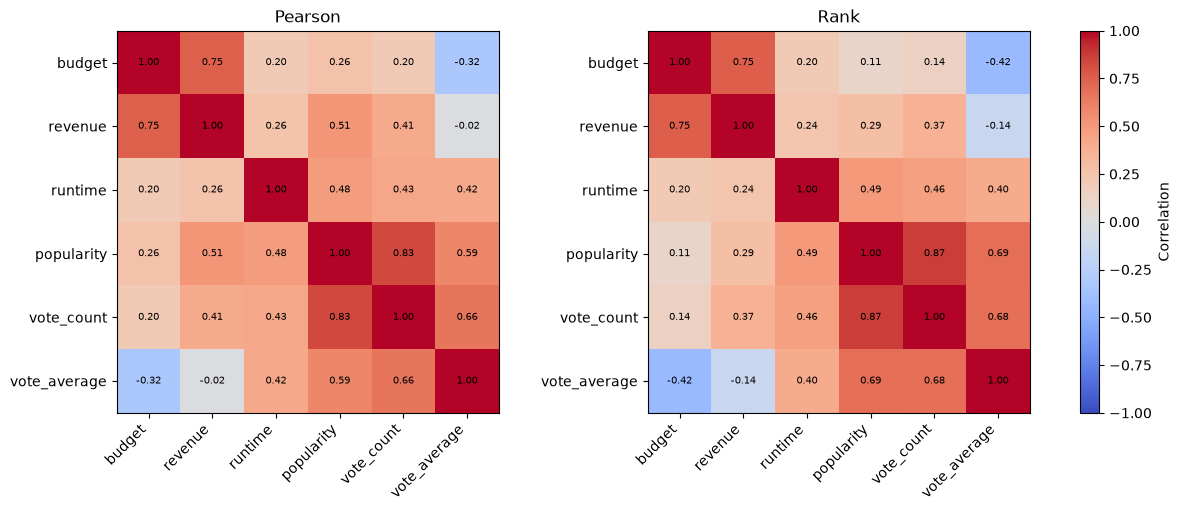

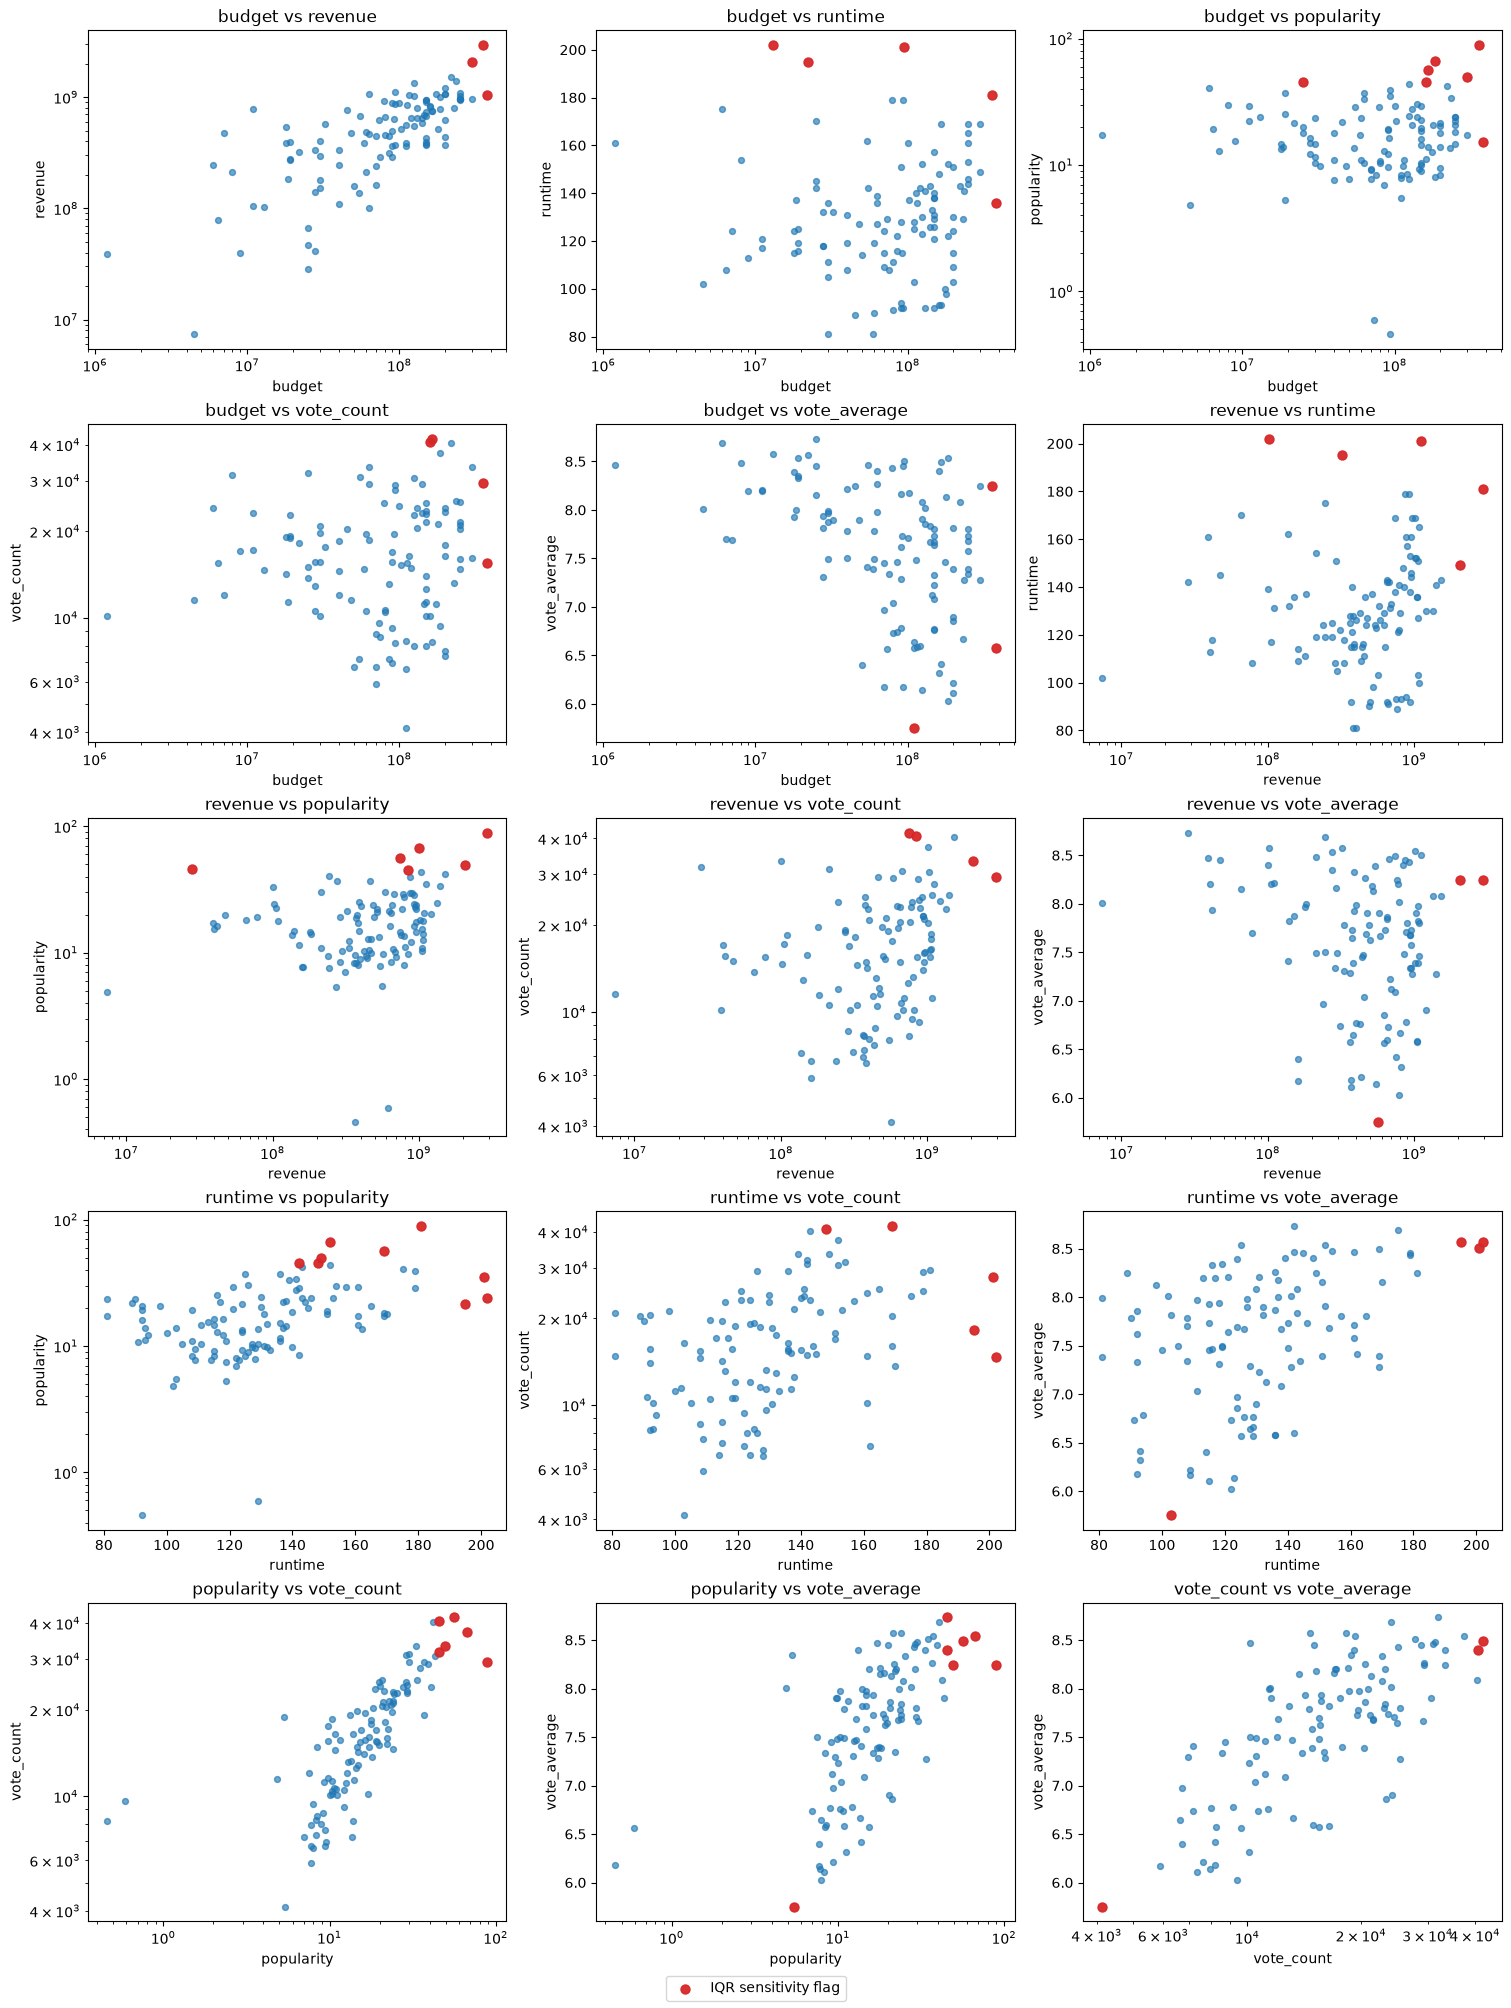

In [13]:
pearson_rank = kpi_movies[kpi_columns].corr(method="pearson")
rank_matrix = kpi_movies[kpi_columns].rank(method="average").corr(method="pearson")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, matrix, title in ((axes[0], pearson_rank, "Pearson"), (axes[1], rank_matrix, "Rank")):
    image = ax.imshow(matrix, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(kpi_columns)), kpi_columns, rotation=45, ha="right")
    ax.set_yticks(range(len(kpi_columns)), kpi_columns)
    ax.set_title(title)
    for i in range(len(kpi_columns)):
        for j in range(len(kpi_columns)):
            ax.text(j, i, f"{matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=axes, fraction=0.025, label="Correlation")
plt.show()

pair_columns = list(combinations(kpi_columns, 2))
columns_per_row = 3
rows = int(np.ceil(len(pair_columns) / columns_per_row))
fig, axes = plt.subplots(rows, columns_per_row, figsize=(15, 4 * rows), constrained_layout=True)
axes = np.array(axes).reshape(-1)
for ax, (x_column, y_column) in zip(axes, pair_columns):
    pair = kpi_movies[["title", x_column, y_column]].dropna()
    pair_flags = kpi_outlier_flags.loc[pair.index, [x_column, y_column]].any(axis=1)
    ax.scatter(pair.loc[~pair_flags, x_column], pair.loc[~pair_flags, y_column], s=18, alpha=0.65)
    ax.scatter(pair.loc[pair_flags, x_column], pair.loc[pair_flags, y_column], s=42, alpha=0.95,
               color="tab:red", label="IQR sensitivity flag")
    ax.set_xlabel(x_column)
    ax.set_ylabel(y_column)
    ax.set_title(f"{x_column} vs {y_column}")
    if x_column in ("budget", "revenue", "popularity", "vote_count"):
        ax.set_xscale("log")
    if y_column in ("budget", "revenue", "popularity", "vote_count"):
        ax.set_yscale("log")
for ax in axes[len(pair_columns):]:
    ax.axis("off")
handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="outside lower center", ncol=2)
plt.show()

#### 4e.2 Predictor combinations and cross-validated KPIs

This ranks combinations of one to three fields for each target with a standardized linear model and 5-fold cross-validation. The mean-prediction baseline provides context, and raw fields remain the primary result.

Top 10 predictor combinations for each target


,target,predictors,predictor_count,n,cv_r2_mean,cv_r2_std,cv_mae_mean,gain_over_mean_baseline
0,budget,revenue + vote_count + vote_average,3,112,0.6168,0.1076,"36,090,632.9152",0.6906
1,budget,revenue + popularity + vote_average,3,112,0.6001,0.1087,"36,499,238.1855",0.6739
2,budget,revenue + runtime + vote_average,3,112,0.5894,0.1336,"37,270,120.2756",0.6632
3,budget,revenue + vote_average,2,112,0.5825,0.1239,"37,481,609.1250",0.6563
4,budget,revenue + vote_count,2,112,0.4870,0.1423,"41,598,640.3596",0.5608
5,budget,revenue + runtime + vote_count,3,112,0.4832,0.1467,"41,704,601.1867",0.5570
6,budget,revenue,1,112,0.4797,0.1481,"42,183,875.1679",0.5535
7,budget,revenue + popularity,2,112,0.4744,0.1533,"41,705,742.5101",0.5482
8,budget,revenue + runtime,2,112,0.4743,0.1507,"42,362,443.6236",0.5481
9,budget,revenue + runtime + popularity,3,112,0.4696,0.1675,"41,379,813.6359",0.5434


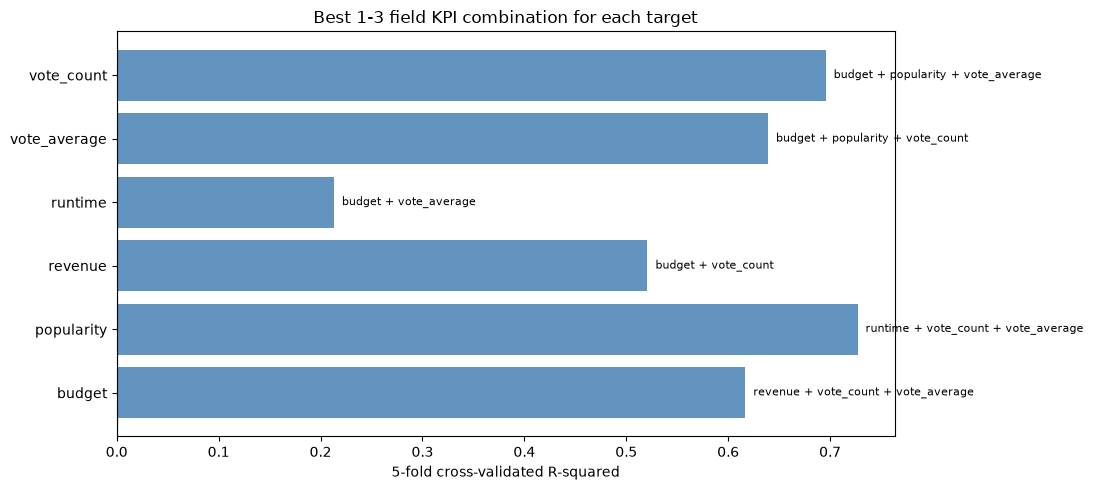

In [14]:
from sklearn.dummy import DummyRegressor

cv = KFold(n_splits=5, shuffle=True, random_state=42)
combination_results = []

for target in kpi_columns:
    predictors = [column for column in kpi_columns if column != target]
    target_frame = kpi_movies[[target] + predictors].dropna()
    y = target_frame[target].to_numpy(dtype=float)
    if len(target_frame) < 5:
        continue

    baseline_X = target_frame[predictors].to_numpy(dtype=float)
    baseline_scores = cross_val_score(DummyRegressor(strategy="mean"), baseline_X, y, cv=cv, scoring="r2")
    baseline_mean = baseline_scores.mean()

    for predictor_count in (1, 2, 3):
        for predictor_tuple in combinations(predictors, predictor_count):
            subset = kpi_movies[[target, *predictor_tuple]].dropna()
            if len(subset) < 5:
                continue
            X = subset[list(predictor_tuple)].to_numpy(dtype=float)
            target_values = subset[target].to_numpy(dtype=float)
            model = make_pipeline(StandardScaler(), LinearRegression())
            scores = cross_val_score(model, X, target_values, cv=cv, scoring="r2")
            mae_scores = cross_val_score(model, X, target_values, cv=cv, scoring="neg_mean_absolute_error")
            combination_results.append({
                "target": target,
                "predictors": " + ".join(predictor_tuple),
                "predictor_count": predictor_count,
                "n": len(subset),
                "cv_r2_mean": scores.mean(),
                "cv_r2_std": scores.std(),
                "cv_mae_mean": -mae_scores.mean(),
                "gain_over_mean_baseline": scores.mean() - baseline_mean,
            })

combination_table = pd.DataFrame(combination_results)
top_combinations = (combination_table.sort_values(["target", "cv_r2_mean"], ascending=[True, False])
                    .groupby("target", group_keys=False).head(10).reset_index(drop=True))
print("Top 10 predictor combinations for each target")
display(top_combinations.round(4))

top_by_target = (combination_table.sort_values(["target", "cv_r2_mean"], ascending=[True, False])
                 .groupby("target", group_keys=False).head(1))
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top_by_target["target"], top_by_target["cv_r2_mean"], color="steelblue", alpha=0.85)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("5-fold cross-validated R-squared")
ax.set_title("Best 1-3 field KPI combination for each target")
for y, (value, predictors) in enumerate(zip(top_by_target["cv_r2_mean"], top_by_target["predictors"])):
    ax.text(value, y, f"  {predictors}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

#### 4e.3 Residual review and strongest relationships

Residual plots show whether a linear summary is reasonable or whether curvature, skew, or influential legit outliers dominate. Legitimate extremes remain visible rather than removed.

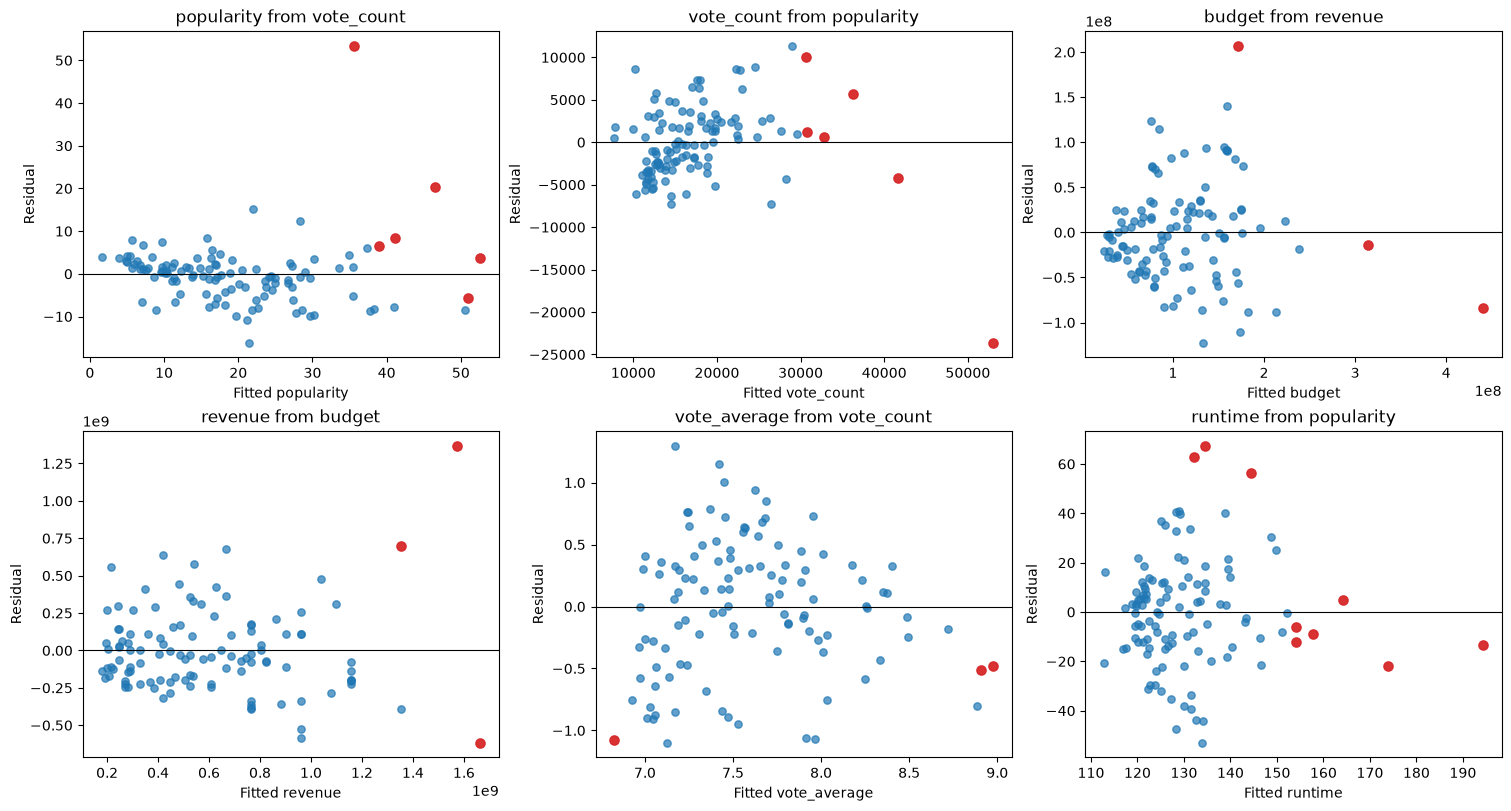

Strongest one-predictor relationship for each target


,target,predictor,raw_r2,rank_correlation,log_r2,n
0,popularity,vote_count,0.6889,0.8692,0.5609,112
1,vote_count,popularity,0.6889,0.8692,0.5609,112
2,budget,revenue,0.5563,0.7527,0.5418,112
3,revenue,budget,0.5563,0.7527,0.5418,112
4,vote_average,vote_count,0.4341,0.6848,0.5229,112
5,runtime,popularity,0.2338,0.4945,0.1909,112


In [15]:
strongest_pairs = (pairwise_table.sort_values("raw_r2", key=lambda series: series.abs(), ascending=False)
                   .drop_duplicates(subset=["target"]).head(6))

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
axes = axes.reshape(-1)
for ax, row in zip(axes, strongest_pairs.to_dict("records")):
    target = row["target"]
    predictor = row["predictor"]
    pair = kpi_movies[["title", target, predictor]].dropna()
    X = pair[[predictor]].to_numpy(dtype=float)
    y = pair[target].to_numpy(dtype=float)
    model = LinearRegression().fit(X, y)
    fitted = model.predict(X)
    residual = y - fitted
    pair_flags = kpi_outlier_flags.loc[pair.index, [target, predictor]].any(axis=1)
    ax.scatter(fitted[~pair_flags.to_numpy()], residual[~pair_flags.to_numpy()], s=28, alpha=0.7)
    ax.scatter(fitted[pair_flags.to_numpy()], residual[pair_flags.to_numpy()], s=44, alpha=0.95,
               color="tab:red", label="IQR sensitivity flag")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel(f"Fitted {target}")
    ax.set_ylabel("Residual")
    ax.set_title(f"{target} from {predictor}")
for ax in axes[len(strongest_pairs):]:
    ax.axis("off")
plt.show()

print("Strongest one-predictor relationship for each target")
display(strongest_pairs[["target", "predictor", "raw_r2", "rank_correlation", "log_r2", "n"]].round(4).reset_index(drop=True))

## 5. Release dates and common categories

Review coverage and the observed range before defining date rules. Frequency tables help identify dominant categories, spelling/label variants, or unexpected missing values.


In [16]:
if "release_date" in movies.columns:
    release_dates = movies["release_date"].dropna()
    print(f"Movies with a release date: {len(release_dates):,} / {len(movies):,}")
    if not release_dates.empty:
        print(f"Observed release-date range: {release_dates.min()} to {release_dates.max()}")
        release_year_counts = (
            release_dates.dt.year.value_counts().sort_index().rename("movie_count")
        )
        print("Earliest release years:")
        display(release_year_counts.head(15).to_frame())
        print("Latest release years:")
        display(release_year_counts.tail(15).to_frame())
else:
    print("No normalized release_date column is available.")

category_columns = [
    column
    for column in ("status", "original_language", "adult", "video")
    if column in movies.columns
]
category_rows = []
for column in category_columns:
    counts = movies[column].value_counts(dropna=False).head(15)
    for value, count in counts.items():
        category_rows.append(
            {
                "field": column,
                "value": value,
                "movie_count": int(count),
                "percent_of_movies": (
                    round(count / len(movies) * 100, 2) if len(movies) else pd.NA
                ),
            }
        )

category_profile = pd.DataFrame(category_rows)
display(category_profile)


Movies with a release date: 112 / 112
Observed release-date range: 1966-12-23 00:00:00 to 2019-06-19 00:00:00
Earliest release years:


,movie_count
release_date,
1966,1
1972,1
1974,1
1975,1
1977,1
1979,1
1980,1
1981,1
1982,1


Latest release years:


,movie_count
release_date,
2004,6
2005,3
2006,5
2007,6
2008,4
2009,3
2010,5
2011,4
2012,3


,field,value,movie_count,percent_of_movies
0,status,Released,112,100.0000
1,original_language,en,110,98.2100
2,original_language,ja,1,0.8900
3,original_language,it,1,0.8900
4,adult,False,112,100.0000
5,video,False,112,100.0000


## 5. Profile relationships

Compare relationship counts to all movies, including movies with zero links. Then inspect the most common genres. The left join preserves links even if a reference label is missing; the match count makes that case visible.


In [17]:
relationship_tables = {
    "genres": tables.movie_genres,
    "production companies": tables.movie_companies,
    "origin countries": tables.movie_origin_countries,
    "production countries": tables.movie_production_countries,
    "spoken languages": tables.movie_spoken_languages,
    "cast credits": tables.cast_credits,
    "crew credits": tables.crew_credits,
}

relationship_rows = []
for relationship_name, links in relationship_tables.items():
    counts_per_movie = links.groupby("movie_id").size().reindex(movies["movie_id"], fill_value=0)
    relationship_rows.append(
        {
            "relationship": relationship_name,
            "link_rows": len(links),
            "movies_with_at_least_one": int(counts_per_movie.gt(0).sum()),
            "movies_with_zero": int(counts_per_movie.eq(0).sum()),
            "mean_link_per_movie_including_zero": (
                float(counts_per_movie.mean()) if len(movies) else pd.NA
            ),
            "median_links_per_movie_including_zero": (
                float(counts_per_movie.median()) if len(movies) else pd.NA
            ),
            "maximum_links_for_one_movie": (
                int(counts_per_movie.max()) if len(movies) else pd.NA
            ),
        }
    )

relationship_profile = pd.DataFrame(relationship_rows)
display(relationship_profile)

genre_counts = (
    tables.movie_genres.groupby("genre_id")
    .size()
    .rename("movie_count")
    .reset_index()
    .merge(
        tables.genres,
        on="genre_id",
        how="left",
        validate="many_to_one",
        indicator="genre_match",
    )
    .sort_values("movie_count", ascending=False)
)
display(genre_counts.head(20))
print("Genre-reference matches:")
display(genre_counts["genre_match"].value_counts(dropna=False).to_frame("link_rows"))


,relationship,link_rows,movies_with_at_least_one,movies_with_zero,mean_link_per_movie_including_zero,median_links_per_movie_including_zero,maximum_links_for_one_movie
0,genres,320,112,0,2.8571,3.0000,5
1,production companies,307,112,0,2.7411,3.0000,7
2,origin countries,117,112,0,1.0446,1.0000,2
3,production countries,154,112,0,1.3750,1.0000,4
4,spoken languages,219,112,0,1.9554,1.0000,6
5,cast credits,7827,112,0,69.8839,65.5000,177
6,crew credits,24929,112,0,222.5804,182.0000,953


,genre_id,movie_count,genre_name,genre_match
5,28,61,Action,both
0,12,60,Adventure,both
11,878,36,Science Fiction,both
9,53,33,Thriller,both
1,14,27,Fantasy,both
3,18,19,Drama,both
6,35,19,Comedy,both
10,80,18,Crime,both
2,16,17,Animation,both
14,10751,17,Family,both


Genre-reference matches:


,link_rows
genre_match,
both,16
left_only,0
right_only,0


# 6. Exploratory categorical relationships

This section is exploratory only; it does not select or recommend titles. It profiles genre, collection/franchise membership, directors, and top-billed cast proxies because these dimensions are relevant to later licensing questions. Other high-cardinality categories are left out of this first pass to avoid noisy, unstable rankings.

The analysis is descriptive, not causal. It does not infer a licensing price: historical box-office revenue is neither profit nor the value of streaming rights. No movie records are removed or modified.

## 6a. Define numeric outcomes

The primary commercial proxy is log revenue, with budget and release year used as context. Audience reach is represented by vote count and popularity; audience response by vote average and a vote-count-shrunk rating. Popularity is a source snapshot and may change. The rating adjustment reduces the influence of ratings based on fewer votes; it is a comparative aid, not a replacement rating.

In [18]:
from IPython.display import display
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


movies = tables.movies.copy()

numeric_outcomes = ["budget", "revenue", "runtime", "popularity", "vote_count", "vote_average"]
for column in numeric_outcomes:
    movies[column] = pd.to_numeric(movies[column], errors="coerce")
movies["release_year"] = pd.to_datetime(movies["release_date"], errors="coerce").dt.year
movies["log_revenue"] = np.log10(movies["revenue"].where(movies["revenue"] > 0))
movies["log_budget"] = np.log10(movies["budget"].where(movies["budget"] > 0))
movies["log_vote_count"] = np.log10(movies["vote_count"].where(movies["vote_count"] > 0))

prior_rating = movies["vote_average"].mean()
prior_votes = movies["vote_count"].quantile(0.25)
movies["rating_adjusted"] = (
    movies["vote_count"] / (movies["vote_count"] + prior_votes) * movies["vote_average"]
    + prior_votes / (movies["vote_count"] + prior_votes) * prior_rating
)
movies["has_collection"] = movies["collection_id"].notna()

print(f"Loaded {len(movies):,} normalized movies from the notebook cache")
print("Outcome coverage:")
display(movies[numeric_outcomes + ["release_year"]].notna().sum().rename("non_missing").to_frame())
print(f"Rating shrinkage prior: cache mean={prior_rating:.3f}; vote-count weight m={prior_votes:,.0f}")

Loaded 112 normalized movies from the notebook cache
Outcome coverage:


,non_missing
budget,112
revenue,112
runtime,112
popularity,112
vote_count,112
vote_average,112
release_year,112


Rating shrinkage prior: cache mean=7.589; vote-count weight m=11,039


## 6b. Univariate category profiles

Start with category size and coverage before comparing outcomes. Genre is multi-label (one movie can belong to several genres); collection membership defines the franchise/standalone split in this cache. A cast order of 0–2 is used only as a transparent proxy for the top three billed actors. Directors are selected from crew credits with the `Director` job.

In [19]:
# Movie-to-category bridge tables; drop duplicate movie/category pairs to prevent credit duplication.
genre_links = (tables.movie_genres.merge(tables.genres, on="genre_id", how="left")
               [["movie_id", "genre_name"]].drop_duplicates())
collection_links = (movies.loc[movies["collection_id"].notna(), ["movie_id", "collection_id"]]
                    .merge(tables.collections[["collection_id", "collection_name"]], on="collection_id", how="left")
                    [["movie_id", "collection_id", "collection_name"]].drop_duplicates())

director_links = (tables.crew_credits.loc[tables.crew_credits["job"].eq("Director"), ["movie_id", "person_id"]]
                  .drop_duplicates()
                  .merge(tables.people[["person_id", "name"]], on="person_id", how="left")
                  .rename(columns={"name": "director"}))

# The top three cast orders are an observable lead-actor proxy, not a definitive starring-role label.
lead_actor_credits = tables.cast_credits.loc[tables.cast_credits["order"].le(2), ["movie_id", "person_id", "order"]]
lead_actor_links = (lead_actor_credits.drop_duplicates(["movie_id", "person_id"])
                    .merge(tables.people[["person_id", "name"]], on="person_id", how="left")
                    .rename(columns={"name": "lead_actor_proxy"}))

profile_rows = [
    {"dimension": "Genre", "category_count": genre_links["genre_name"].nunique(), "movie_or_credit_links": len(genre_links), "unit": "movie-genre links"},
    {"dimension": "Collections", "category_count": collection_links["collection_id"].nunique(), "movie_or_credit_links": len(collection_links), "unit": "movie-collection links"},
    {"dimension": "Franchise vs standalone", "category_count": 2, "movie_or_credit_links": len(movies), "unit": "movies"},
    {"dimension": "Directors", "category_count": director_links["director"].nunique(), "movie_or_credit_links": len(director_links), "unit": "director-movie credits"},
    {"dimension": "Top-three cast proxy", "category_count": lead_actor_links["lead_actor_proxy"].nunique(), "movie_or_credit_links": len(lead_actor_links), "unit": "actor-movie credits"},
]
display(pd.DataFrame(profile_rows))

print("Genre frequency (movies can appear in multiple rows):")
genre_counts = genre_links.groupby("genre_name")["movie_id"].nunique().sort_values(ascending=False)
display(genre_counts.rename("movies").to_frame())

print("Collection membership frequency:")
collection_counts = (collection_links.groupby(["collection_id", "collection_name"])["movie_id"]
                     .nunique().sort_values(ascending=False).rename("observed_movies").reset_index())
display(collection_counts.head(15))

franchise_counts = movies["has_collection"].map({True: "Collection-linked", False: "Standalone"}).value_counts()
print("Collection-linked vs standalone coverage:")
display(franchise_counts.rename("movies").to_frame())

print("Most frequent directors in this cache:")
director_counts = (director_links.groupby("director")["movie_id"].nunique()
                   .sort_values(ascending=False).rename("distinct_movies").reset_index())
display(director_counts.head(15))

print("Most frequent top-three cast proxies:")
actor_counts = (lead_actor_links.groupby("lead_actor_proxy")["movie_id"].nunique()
                .sort_values(ascending=False).rename("distinct_movies").reset_index())
display(actor_counts.head(15))

print("Repeat-credit coverage (a prerequisite for any reliability claim):")
display(pd.DataFrame([
    {"role": "Director", "people_with_2plus_titles": int(director_counts["distinct_movies"].ge(2).sum()), "people_with_3plus_titles": int(director_counts["distinct_movies"].ge(3).sum())},
    {"role": "Top-three cast proxy", "people_with_2plus_titles": int(actor_counts["distinct_movies"].ge(2).sum()), "people_with_3plus_titles": int(actor_counts["distinct_movies"].ge(3).sum())},
]))

,dimension,category_count,movie_or_credit_links,unit
0,Genre,16,320,movie-genre links
1,Collections,32,96,movie-collection links
2,Franchise vs standalone,2,112,movies
3,Directors,66,122,director-movie credits
4,Top-three cast proxy,184,336,actor-movie credits


Genre frequency (movies can appear in multiple rows):


,movies
genre_name,
Action,61
Adventure,60
Science Fiction,36
Thriller,33
Fantasy,27
Comedy,19
Drama,19
Crime,18
Family,17


Collection membership frequency:


,collection_id,collection_name,observed_movies
0,1241,Harry Potter Collection,8
1,10,Star Wars Collection,6
2,295,Pirates of the Caribbean Collection,5
3,87359,Mission: Impossible Collection,5
4,2150,Shrek Collection,4
5,1570,Die Hard Collection,4
6,528,The Terminator Collection,4
7,84,Indiana Jones Collection,4
8,10194,Toy Story Collection,4
9,86311,The Avengers Collection,4


Collection-linked vs standalone coverage:


... (3 outputs left out)

Most frequent top-three cast proxies:


,lead_actor_proxy,distinct_movies
0,Emma Watson,8
1,Daniel Radcliffe,8
2,Rupert Grint,8
3,Harrison Ford,8
4,Robert Downey Jr.,7
5,Ian McKellen,6
6,Al Pacino,5
7,Christian Bale,5
8,Tom Cruise,5
9,Johnny Depp,5


Repeat-credit coverage (a prerequisite for any reliability claim):


,role,people_with_2plus_titles,people_with_3plus_titles
0,Director,28,13
1,Top-three cast proxy,61,44


## 6c. Category distributions against numeric outcomes

Report median outcomes and sample counts so a single blockbuster is less likely to dominate the category summary. Revenue remains nominal historical gross; the next section adjusts the comparison for budget and release year. Franchise totals below include only films present in this cache, not necessarily every installment in a real-world collection.

Genre outcomes; use group sizes and medians together:


,genre_name,movies,median_revenue,median_log_revenue,median_budget,median_popularity,median_vote_count,median_vote_average,median_adjusted_rating
0,Action,61,"585,174,222.0000",8.7670,"115,000,000.0000",14.6840,"15,440.0000",7.4500,7.5250
1,Adventure,60,"781,017,020.0000",8.8930,"125,000,000.0000",16.7800,"17,712.5000",7.6100,7.6040
12,Science Fiction,36,"529,855,930.0000",8.7240,"107,500,000.0000",17.0740,"17,357.0000",7.7420,7.6760
13,Thriller,33,"366,101,666.0000",8.5640,"85,000,000.0000",10.9620,"11,335.0000",7.4500,7.5230
7,Fantasy,27,"926,287,400.0000",8.9670,"150,000,000.0000",22.8780,"20,350.0000",7.6820,7.6500
3,Comedy,19,"563,749,323.0000",8.7510,"80,000,000.0000",13.9420,"14,528.0000",7.5000,7.5440
5,Drama,19,"245,066,411.0000",8.3890,"40,000,000.0000",19.0400,"18,194.0000",8.2500,8.0180
4,Crime,18,"258,904,666.5000",8.4130,"42,000,000.0000",18.8630,"17,901.0000",8.1570,7.9180
2,Animation,17,"650,000,000.0000",8.8130,"92,000,000.0000",16.3120,"15,594.0000",7.6230,7.6090
6,Family,17,"650,000,000.0000",8.8130,"92,000,000.0000",16.3120,"15,594.0000",7.6230,7.6090


Genres with fewer than 10 cached movies are shown in the univariate counts but omitted from outcome comparisons:


,movies
genre_name,
Horror,4
Mystery,4
Romance,2
History,1
War,1
Western,1


Collection-linked vs standalone outcomes:


,type,movies,median_revenue,median_log_revenue,median_budget,median_popularity,median_vote_count,median_vote_average,median_adjusted_rating
0,Collection-linked,96,"578,937,111.0000",8.7630,"101,000,000.0000",14.6880,"15,482.5000",7.6010,7.5960
1,Standalone,16,"161,802,536.5000",8.1850,"25,000,000.0000",21.1730,"18,854.5000",8.4260,8.1390


Collections with at least two observed movies (not necessarily complete bundles):


,collection,movies,median_revenue,median_log_revenue,median_budget,median_popularity,median_vote_count,median_vote_average,median_adjusted_rating,observed_gross_total
27,The Lord of the Rings Collection,3,"926,287,400.0000",8.9670,"93,000,000.0000",34.9410,"27,846.0000",8.4510,8.2130,2916544743
22,The Godfather Collection,3,"136,766,062.0000",8.1360,"13,000,000.0000",24.0440,"14,626.0000",8.5730,8.1500,484432473
19,The Avengers Collection,4,"1,785,615,277.0000",9.2470,"267,500,000.0000",45.7850,"31,401.0000",8.1660,8.0230,7919284026
11,Kill Bill Collection,2,"166,532,768.5000",8.2200,"30,000,000.0000",13.1190,"17,713.0000",7.9210,7.7940,333065537
21,The Dark Knight Collection,3,"1,008,480,529.0000",9.0040,"185,000,000.0000",20.5660,"25,331.0000",7.8010,7.7370,2463740489
5,Harry Potter Collection,8,"936,085,967.5000",8.9710,"140,000,000.0000",26.1000,"22,850.5000",7.7680,7.7080,7759777709
1,Back to the Future Collection,3,"332,861,197.0000",8.5220,"40,000,000.0000",10.8610,"14,528.0000",7.7840,7.7000,969485632
31,Toy Story Collection,4,"782,345,752.5000",8.8620,"132,500,000.0000",16.5580,"16,025.0000",7.7200,7.6670,3039690868
18,Star Wars Collection,6,"712,398,167.5000",8.8510,"72,675,000.0000",10.3460,"17,000.5000",7.6900,7.6520,4432411744
7,Indiana Jones Collection,4,"432,048,888.5000",8.6330,"38,000,000.0000",11.0710,"11,037.0000",7.6040,7.6000,1983841081


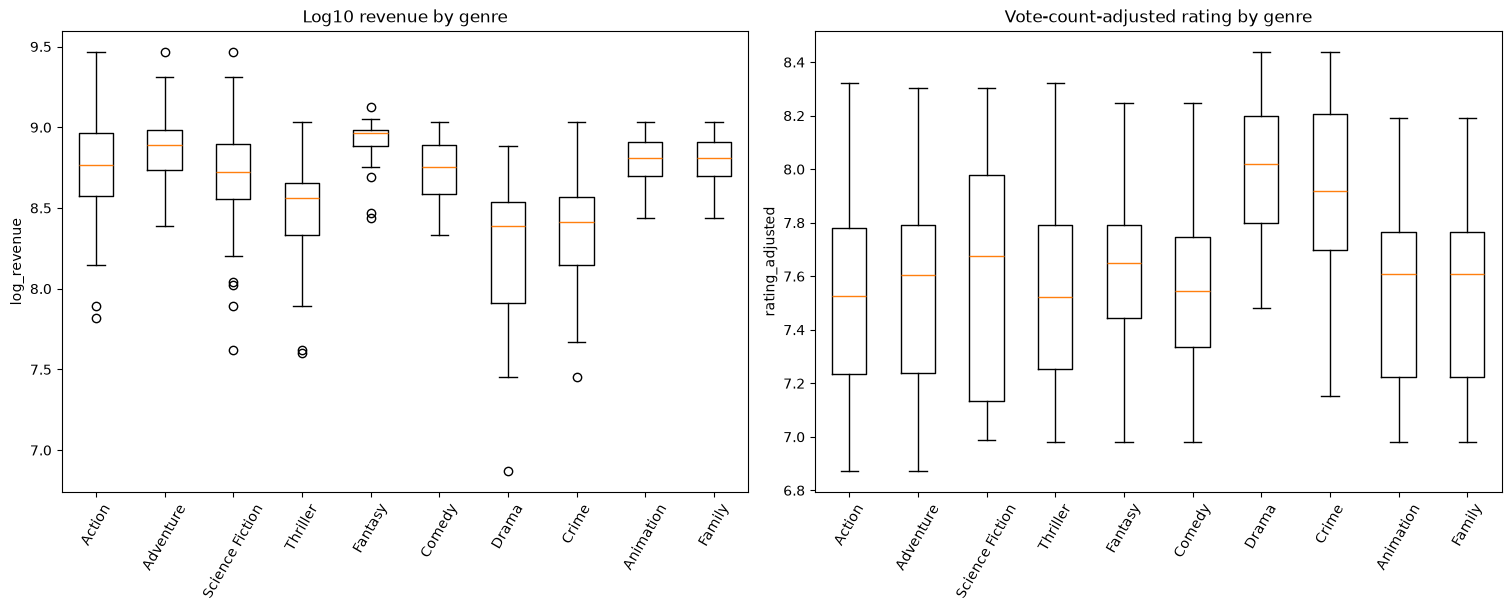

In [20]:
outcome_columns = ["revenue", "log_revenue", "budget", "popularity", "vote_count", "vote_average", "rating_adjusted"]

def category_outcomes(links, category_column, minimum_movies=1):
    joined = links[["movie_id", category_column]].drop_duplicates().merge(
        movies[["movie_id", *outcome_columns]], on="movie_id", how="left"
    )
    summary = joined.groupby(category_column).agg(
        movies=("movie_id", "nunique"),
        median_revenue=("revenue", "median"),
        median_log_revenue=("log_revenue", "median"),
        median_budget=("budget", "median"),
        median_popularity=("popularity", "median"),
        median_vote_count=("vote_count", "median"),
        median_vote_average=("vote_average", "median"),
        median_adjusted_rating=("rating_adjusted", "median"),
    ).reset_index()
    return summary.loc[summary["movies"].ge(minimum_movies)].sort_values("movies", ascending=False)

genre_outcomes = category_outcomes(genre_links, "genre_name", minimum_movies=10)
print("Genre outcomes; use group sizes and medians together:")
display(genre_outcomes.round(3))
print("Genres with fewer than 10 cached movies are shown in the univariate counts but omitted from outcome comparisons:")
display(genre_counts.loc[genre_counts.lt(10)].rename("movies").to_frame())

franchise_type_links = movies[["movie_id", "has_collection"]].copy()
franchise_type_links["type"] = franchise_type_links["has_collection"].map({True: "Collection-linked", False: "Standalone"})
franchise_vs_standalone = category_outcomes(franchise_type_links, "type")
print("Collection-linked vs standalone outcomes:")
display(franchise_vs_standalone.round(3))

collection_outcomes = category_outcomes(collection_links.rename(columns={"collection_name": "collection"}), "collection", minimum_movies=2)
collection_outcomes["observed_gross_total"] = collection_links.merge(
    movies[["movie_id", "revenue"]], on="movie_id", how="left"
).groupby("collection_name")["revenue"].sum(min_count=1).reindex(collection_outcomes["collection"]).to_numpy()
print("Collections with at least two observed movies (not necessarily complete bundles):")
display(collection_outcomes.sort_values(["median_adjusted_rating", "median_log_revenue"], ascending=False).round(3).head(20))

# Grouped visuals emphasize distributions, not just category averages.
plot_genres = genre_outcomes.loc[genre_outcomes["movies"].ge(10), "genre_name"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
for ax, outcome, title in ((axes[0], "log_revenue", "Log10 revenue by genre"),
                           (axes[1], "rating_adjusted", "Vote-count-adjusted rating by genre")):
    values = [genre_links.loc[genre_links["genre_name"].eq(genre), ["movie_id"]]
              .merge(movies[["movie_id", outcome]], on="movie_id", how="left")[outcome].dropna().to_numpy()
              for genre in plot_genres]
    ax.boxplot(values, tick_labels=plot_genres, showfliers=True)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=60)
    ax.set_ylabel(outcome)
plt.show()

## 6d. Multivariate genre comparisons

A category can appear valuable because it tends to occur in newer, higher-budget, or franchise films. This exploratory model compares log revenue while controlling for log budget, release year, and collection membership, then tests whether common genre indicators add predictive signal in held-out folds. Genre labels overlap, so a genre coefficient means association with that tag while holding the included fields constant—not a causal genre effect.

In [21]:
# Focus on genres appearing in at least 15 cached movies; keep the cutoff visible and inspect group counts above.
minimum_genre_movies = 15
selected_genres = genre_counts.loc[genre_counts.ge(minimum_genre_movies)].index.tolist()
genre_wide = pd.crosstab(genre_links["movie_id"], genre_links["genre_name"]).reindex(columns=selected_genres, fill_value=0)
genre_wide.columns = [f"genre_{name.replace(' ', '_')}" for name in genre_wide.columns]

model_frame = movies[["movie_id", "log_revenue", "log_budget", "release_year", "has_collection"]].merge(
    genre_wide, left_on="movie_id", right_index=True, how="left"
)
genre_feature_columns = list(genre_wide.columns)
model_frame[genre_feature_columns] = model_frame[genre_feature_columns].fillna(0)
model_frame = model_frame.dropna(subset=["log_revenue", "log_budget", "release_year"])
model_frame["has_collection"] = model_frame["has_collection"].astype(int)

control_columns = ["log_budget", "release_year", "has_collection"]
full_feature_columns = control_columns + genre_feature_columns
X_control = model_frame[control_columns].to_numpy(dtype=float)
X_genres = model_frame[full_feature_columns].to_numpy(dtype=float)
y_log_revenue = model_frame["log_revenue"].to_numpy(dtype=float)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

model_comparison = []
for label, X in (("Controls only", X_control), ("Controls + common genres", X_genres)):
    r2 = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), X, y_log_revenue, cv=cv, scoring="r2")
    mae = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), X, y_log_revenue, cv=cv, scoring="neg_mean_absolute_error")
    model_comparison.append({"model": label, "n_movies": len(model_frame), "cv_r2_mean": r2.mean(),
                             "cv_r2_sd": r2.std(), "cv_mae_log10": -mae.mean()})
display(pd.DataFrame(model_comparison).round(4))

full_model = LinearRegression().fit(X_genres, y_log_revenue)
genre_effects = pd.DataFrame({"feature": full_feature_columns, "coefficient_log10_revenue": full_model.coef_})
genre_effects = genre_effects.loc[genre_effects["feature"].str.startswith("genre_")].copy()
genre_effects["approx_percent_difference_vs_no_tag"] = (10 ** genre_effects["coefficient_log10_revenue"] - 1) * 100
print("Exploratory adjusted genre associations (not causal; genre tags overlap):")
display(genre_effects.sort_values("coefficient_log10_revenue", ascending=False).round(3))

,model,n_movies,cv_r2_mean,cv_r2_sd,cv_mae_log10
0,Controls only,112,0.5019,0.2004,0.2116
1,Controls + common genres,112,0.4996,0.1705,0.2086


Exploratory adjusted genre associations (not causal; genre tags overlap):


,feature,coefficient_log10_revenue,approx_percent_difference_vs_no_tag
4,genre_Adventure,0.2230,66.9460
10,genre_Crime,0.0640,15.8120
12,genre_Animation,0.0450,10.9450
11,genre_Family,0.0450,10.9450
8,genre_Comedy,0.0070,1.5610
5,genre_Science_Fiction,0.0060,1.3480
7,genre_Fantasy,0.0000,0.0920
3,genre_Action,-0.0110,-2.5150
6,genre_Thriller,-0.0700,-14.7970
9,genre_Drama,-0.1660,-31.7230


### 6e. Collection-level patterns

The broad collection-linked/standalone comparison is not enough to pick a bundle. Review each collection’s observed film count, per-film medians, aggregate gross, and adjusted-revenue residuals. Require at least two observed titles for a collection-level pattern; even then, verify whether the cache contains the full bundle before using totals.

In [22]:
# Cross-validated revenue residuals provide a relative benchmark after budget, year, collection status, and common genres.
cv_predictions = cross_val_predict(make_pipeline(StandardScaler(), LinearRegression()), X_genres, y_log_revenue, cv=cv)
model_frame = model_frame.copy()
model_frame["cv_log_revenue_residual"] = y_log_revenue - cv_predictions
model_frame["revenue_vs_expected_pct"] = (10 ** model_frame["cv_log_revenue_residual"] - 1) * 100

franchise_residual_summary = (model_frame.groupby("has_collection").agg(
    movies=("movie_id", "nunique"),
    median_log_revenue_residual=("cv_log_revenue_residual", "median"),
    median_revenue_vs_expected_pct=("revenue_vs_expected_pct", "median"),
).reset_index())
franchise_residual_summary["type"] = franchise_residual_summary["has_collection"].map({1: "Collection-linked", 0: "Standalone"})
print("Out-of-fold relative revenue benchmark by collection membership:")
display(franchise_residual_summary[["type", "movies", "median_log_revenue_residual", "median_revenue_vs_expected_pct"]].round(3))

collection_performance = (collection_links.merge(
    model_frame[["movie_id", "cv_log_revenue_residual", "revenue_vs_expected_pct"]], on="movie_id", how="inner"
).groupby(["collection_id", "collection_name"]).agg(
    observed_movies=("movie_id", "nunique"),
    median_adjusted_residual=("cv_log_revenue_residual", "median"),
    median_revenue_vs_expected_pct=("revenue_vs_expected_pct", "median"),
).reset_index())
collection_performance = collection_performance.loc[collection_performance["observed_movies"].ge(2)]
collection_performance = collection_performance.merge(
    collection_outcomes[["collection", "median_adjusted_rating", "median_vote_count", "observed_gross_total"]],
    left_on="collection_name", right_on="collection", how="left"
).drop(columns="collection")
print("Observed multi-film collections, with sample size and out-of-fold relative revenue:")
display(collection_performance.sort_values("median_adjusted_residual", ascending=False).round(3).head(20))

Out-of-fold relative revenue benchmark by collection membership:


,type,movies,median_log_revenue_residual,median_revenue_vs_expected_pct
0,Standalone,16,0.1370,37.7530
1,Collection-linked,96,-0.0250,-5.5370


Observed multi-film collections, with sample size and out-of-fold relative revenue:


,collection_id,collection_name,observed_movies,median_adjusted_residual,median_revenue_vs_expected_pct,median_adjusted_rating,median_vote_count,observed_gross_total
18,31562,The Bourne Collection,3,0.3340,115.7460,7.5270,"8,757.0000",945358579
19,86311,The Avengers Collection,4,0.2610,83.5110,8.0230,"31,401.0000",7919284026
4,263,The Dark Knight Collection,3,0.2460,76.1350,7.7370,"25,331.0000",2463740489
2,119,The Lord of the Rings Collection,3,0.2040,59.8460,8.2130,"27,846.0000",2916544743
13,2344,The Matrix Collection,3,0.1110,28.9980,7.3210,"12,552.0000",1627105295
0,10,Star Wars Collection,6,0.1020,26.5070,7.6520,"17,000.5000",4432411744
10,1241,Harry Potter Collection,8,0.0080,1.9760,7.7080,"22,850.5000",7759777709
16,8354,Ice Age Collection,3,-0.0020,-0.5460,7.2230,"10,676.0000",1930942709
17,10194,Toy Story Collection,4,-0.0070,-1.4920,7.6670,"16,025.0000",3039690868
8,328,Jurassic Park Collection,3,-0.0160,-3.6340,7.1130,"9,617.0000",2045874038


## 6f. Director and lead-actor associations

Raw talent averages reward people attached to large-budget or franchise titles. Instead, compare each credited title with an out-of-fold expected log revenue based on budget, release year, collection status, and common genres. A positive residual means the title earned more than that baseline expected; it does not prove that the person caused the result. Rankings require at least three distinct observed titles and should be treated as preliminary.

Directors with at least three distinct movies in this cache:


,person,distinct_titles,median_adjusted_revenue_residual,median_revenue_vs_expected_pct,median_adjusted_rating,median_vote_count,median_popularity,role
11,Christopher Nolan,7,0.2070,61.1230,7.9790,"25,331.0000",20.5660,Director
44,Lilly Wachowski,3,0.1110,28.9980,7.3210,"12,552.0000",14.4690,Director
41,Lana Wachowski,3,0.1110,28.9980,7.3210,"12,552.0000",14.4690,Director
20,George Lucas,4,0.1020,26.5070,7.2720,"15,975.5000",10.3460,Director
27,James Cameron,3,0.0310,7.4620,7.7980,"15,201.0000",19.1800,Director
51,Peter Jackson,6,0.0230,6.0010,7.8790,"22,675.0000",25.4240,Director
64,Steven Spielberg,8,-0.0020,-0.4790,7.6940,"11,791.0000",11.2930,Director
52,Quentin Tarantino,3,-0.0260,-5.8300,7.8330,"19,739.0000",14.6840,Director
15,David Yates,4,-0.0290,-5.7870,7.6670,"21,477.0000",24.0090,Director
59,Robert Zemeckis,4,-0.0620,-5.6640,7.8950,"18,653.5000",18.1000,Director


Top-three cast proxies with at least three distinct movies:


,person,distinct_titles,median_adjusted_revenue_residual,median_revenue_vs_expected_pct,median_adjusted_rating,median_vote_count,median_popularity,role
27,Chris Evans,3,0.3110,104.6820,8.0670,"33,418.0000",49.4660,Top-three cast proxy
120,Matt Damon,4,0.2970,98.9270,7.5340,"9,668.0000",10.0350,Top-three cast proxy
115,Mark Ruffalo,3,0.2100,62.3390,7.9780,"29,384.0000",42.1050,Top-three cast proxy
178,Viggo Mortensen,3,0.2040,59.8460,8.2130,"27,846.0000",34.9410,Top-three cast proxy
51,Elijah Wood,3,0.2040,59.8460,8.2130,"27,846.0000",34.9410,Top-three cast proxy
19,Carrie Fisher,3,0.1960,56.9530,8.0070,"19,137.0000",13.2800,Top-three cast proxy
114,Mark Hamill,3,0.1960,56.9530,8.0070,"19,137.0000",13.2800,Top-three cast proxy
147,Robert Downey Jr.,7,0.1820,51.9510,7.6460,"29,204.0000",33.7550,Top-three cast proxy
29,Christian Bale,5,0.1780,50.7710,7.7370,"23,544.0000",18.6860,Top-three cast proxy
124,Michael Caine,3,0.1780,50.7710,7.9790,"23,544.0000",18.6860,Top-three cast proxy


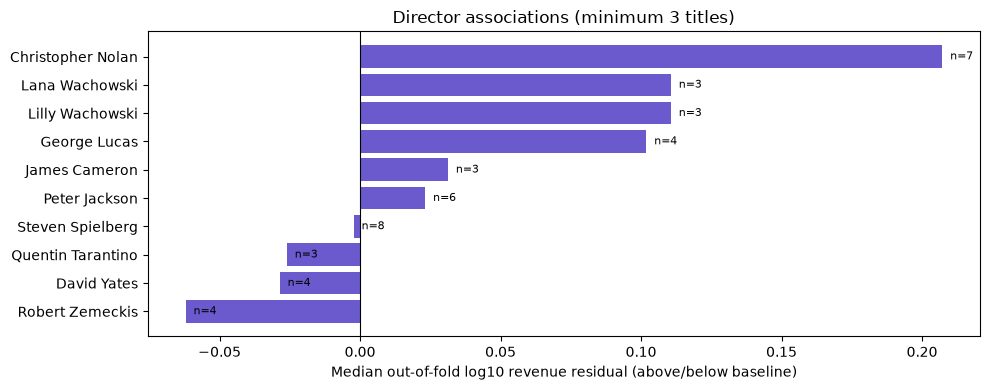

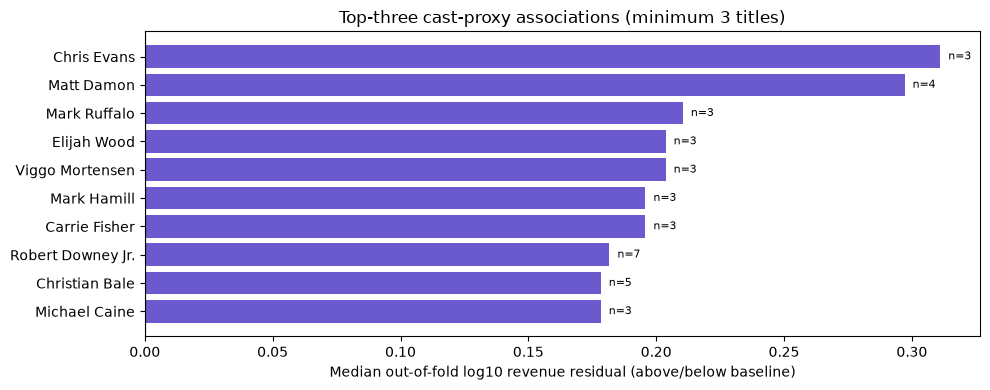

In [23]:
movie_residuals = model_frame[["movie_id", "cv_log_revenue_residual", "revenue_vs_expected_pct"]]

def talent_summary(links, name_column, role, minimum_titles=3):
    joined = links[["movie_id", name_column]].drop_duplicates().merge(movie_residuals, on="movie_id", how="inner")
    joined = joined.merge(movies[["movie_id", "rating_adjusted", "vote_count", "popularity"]], on="movie_id", how="left")
    result = joined.groupby(name_column).agg(
        distinct_titles=("movie_id", "nunique"),
        median_adjusted_revenue_residual=("cv_log_revenue_residual", "median"),
        median_revenue_vs_expected_pct=("revenue_vs_expected_pct", "median"),
        median_adjusted_rating=("rating_adjusted", "median"),
        median_vote_count=("vote_count", "median"),
        median_popularity=("popularity", "median"),
    ).reset_index().rename(columns={name_column: "person"})
    result["role"] = role
    return result.loc[result["distinct_titles"].ge(minimum_titles)].sort_values(
        "median_adjusted_revenue_residual", ascending=False
    )

director_performance = talent_summary(director_links, "director", "Director")
actor_performance = talent_summary(lead_actor_links, "lead_actor_proxy", "Top-three cast proxy")
print("Directors with at least three distinct movies in this cache:")
display(director_performance.head(15).round(3))
print("Top-three cast proxies with at least three distinct movies:")
display(actor_performance.head(15).round(3))

# Plot shows both adjusted effect and how much evidence supports each person.
for frame, title in ((director_performance, "Director associations"), (actor_performance, "Top-three cast-proxy associations")):
    plot_frame = frame.head(10).sort_values("median_adjusted_revenue_residual")
    if plot_frame.empty:
        print(f"No {title.lower()} meet the minimum-title threshold.")
        continue
    fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(plot_frame))))
    ax.barh(plot_frame["person"], plot_frame["median_adjusted_revenue_residual"], color="slateblue")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Median out-of-fold log10 revenue residual (above/below baseline)")
    ax.set_title(title + " (minimum 3 titles)")
    for y_pos, count in enumerate(plot_frame["distinct_titles"]):
        ax.text(plot_frame["median_adjusted_revenue_residual"].iloc[y_pos], y_pos,
                f"  n={count}", va="center", fontsize=8)
    plt.tight_layout()
    plt.show()

## 6g. Interpretation and limits

Use the outputs below to understand associations and data limitations, not to make a shortlist or licensing recommendation:

- **Franchise versus standalone:** Compare per-film performance and the out-of-fold relative-revenue benchmark. Use observed collection totals only when bundle completeness is verified.
- **Genre:** Treat an adjusted genre coefficient as a conditional association. Multi-genre films make categories overlap, and a small sample limits precise ranking.
- **Directors and lead actors:** Treat residual rankings as hypotheses. Require adequate title counts, review the titles individually, and do not infer causal talent value from observational credits.
- **Scope:** These tables are exploratory findings only. They do not rank licensing targets, select the strongest franchise, or estimate a deal price.
- Popularity and vote count overlap; do not treat them as independent evidence. Box-office gross is not profit or streaming value.

All results reflect this 112-film cache and its coverage, not complete collection histories or complete filmographies of people.

## 7. What this EDA supports—and what it cannot determine

### What the current analysis supports

- This is a snapshot of **112 cached movies**. All 112 have a release date in the current cache, spanning **1966-12-23 through 2019-06-19**. Numeric summaries describe this sample, not the full film market.
- IQR flags are screening signals, not validity rules. The reviewed high budget/revenue and long-runtime values are plausible extremes in context; high popularity remains a source-snapshot value that should be verified before relying on it. The analysis retains unusual values and checks how they influence relationships rather than treating them as automatic errors.
- There are clear **associations** in this sample: budget and revenue (Pearson 0.746; rank correlation 0.753), popularity and vote count (0.830; 0.869), and vote count and vote average (0.659; 0.685). The first two relationships remain similar when IQR-flagged rows are excluded in sensitivity checks. This suggests they are not driven only by the flagged extremes.
- Runtime has a moderate association with popularity and vote average in this sample. Revenue and vote average show little linear relationship. These are descriptive patterns, not evidence that changing one field causes another to change.
- The categorical analysis covers 16 genres (320 movie-genre links), 32 collections, 66 directors, and 184 top-three cast proxies. These are counts within the 112-title cache, not complete industry catalogues. Sparse genres are excluded from outcome comparisons using the documented minimum group sizes.
- Common genre indicators added little predictive information beyond budget, release year, and collection status in the five-fold comparison: cross-validated R-squared changed from about 0.502 to 0.500, while log-revenue MAE changed slightly from 0.212 to 0.209. The result is mixed and does not establish that genre is unimportant; it says this sample/model did not show an improvement in held-out R-squared.
- In the model's out-of-fold revenue-residual summaries, standalone movies had a median residual equivalent to about +37.8% versus the model expectation, while collection-linked movies were about -5.5%. This is a sample- and model-dependent descriptive contrast, not evidence that standalones are inherently better; only 16 titles are standalone and collection coverage may be incomplete.
- Talent summaries show varied adjusted residuals among people with at least three observed titles (13 directors and 44 top-three cast proxies meet that threshold). These indicate possible patterns to investigate, not reliable or causal director/actor effects. Cast order is only a lead-actor proxy.

### What cannot be determined from this analysis

- It cannot establish causal effects, reliable future prediction, or what an audience will prefer. The models are exploratory and use a small, selected cache.
- It cannot establish that franchises outperform standalones, identify defensible licensing targets, or determine the value/price of a license. Historical nominal box-office revenue is not profit or streaming value; rights availability, territory, term, price, and platform performance are absent.
- It cannot establish reliable director or actor effects, rank talent for future titles, or separate a person's contribution from collaborators, budget, genre, franchise, release year, and selection effects. The cache does not represent complete filmographies.
- The genre model's small cross-validation differences are not evidence of a stable predictive gain or proof that genres have no value. Genre labels overlap, groups are uneven, and comparisons depend on this selected sample.
- The collection comparison does not establish that franchise bundles outperform standalone titles. Collection membership in this cache may be incomplete, and only 16 movies are standalone.
- Popularity is time-sensitive; vote counts and ratings are audience measures rather than direct measures of licensing value. The categorical residual summaries are not recommendations, causal effects, or deal-price estimates.

**Relevance:** this EDA identifies data-quality concerns, plausible extremes, sample patterns, and relationships worth investigating. It narrows questions for later analysis, but it does not itself justify a licensing decision or a causal claim.